# 2024 OPM FEVS – Keşifçi Veri Analizi (EDA)

Bu notebook `01_veri_okuma.ipynb` ile hazırlanan temiz veriyi kullanır.

**İçerik**
1. Veri tablosu ve değişken sözlüğü (her değişkenin türü)
2. **Sürekli** değişkenler – tanımlayıcı istatistikler, histogram, kutu grafiği, korelasyon
3. **Nominal / ikili kategorik** değişkenler – frekans tabloları ve çubuk grafikler
4. **Sıralı kategorik (Likert)** maddeler – pozitif / nötr / negatif dağılımları
5. Çapraz analizler – demografik gruplara göre indeks skorları, ajans karşılaştırması
6. Tüm tabloların Excel'e aktarılması

> Tüm yüzdeler teknik rapordaki gibi **`POSTWT` ile ağırlıklıdır**; "Bilmiyorum" (X) ve boş cevaplar paydaya dahil edilmez.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from textwrap import fill

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # notebook'lar notebooks/ klasöründen çalışır
    ROOT = ROOT.parent
DATA, FIG, TAB = ROOT / "data", ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

def kaydet(ad):
    """Grafiği reports/figures klasörüne kaydeder ve gösterir."""
    plt.savefig(FIG / f"{ad}.png", dpi=110, bbox_inches="tight")
    plt.show()
df = pd.read_pickle(DATA / "fevs2024_clean.pkl")
cb = pd.read_excel(DATA / "2024" / "2024_OPM_FEVS_PRDF_Codebook.xlsx", sheet_name=None)
print(f"{len(df):,} satır, {df.shape[1]} kolon")

674,207 satır, 98 kolon


In [2]:
# --- Grafik stili ---
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SERIES = [BLUE, ORANGE, AQUA, YELLOW, "#e87ba4", "#008300", "#6250d6", "#e34948"]
POS, NEU, NEG = "#2a78d6", "#c3c2b7", "#e34948"          # ıraksak: mavi / gri / kırmızı
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": INK2, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 100,
})

## 1. Veri tablosu

In [3]:
df.head(20)

,RandomID,POSTWT,agency,level1,agency_name,level1_name,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15,Q17,Q18,Q19,Q20,Q21,Q22,Q23,Q24,Q25,Q26,Q27,Q28,Q29,Q30,Q31,Q32,Q33,Q34,Q35,Q36,Q37,Q38,Q39,Q40,Q41,Q42,Q43,Q44,Q45,Q46,Q47,Q48,Q49,Q50,Q51,Q52,Q53,Q54,Q55,Q56,Q57,Q58,Q59,Q60,Q61,Q62,Q63,Q64,Q65,Q66,Q67,Q68,Q69,Q70,Q71,Q72,Q86,Q87,Q88,Q89,Q90,Q16_1,Q16_2,Q16_3,Q16_4,Q16_5,Q16_6,Q91,DRNO,DHISP,DDIS,DAGEGRP,DSUPER,DFEDTEN,DSEX,DMIL,DLEAVING
0,112970976817,1.60,XX,XXZZ,All Other Agencies,All Other Agencies,3,4,4,4,1,<NA>,5,4,4,4,4,4,5,4,4,3,4,4,4,5,4,4,4,5,5,4,4,3,3,3,3,3,2,4,4,4,4,3,4,4,1,3,<NA>,3,5,3,4,3,3,4,4,3,3,1,2,3,3,4,4,3,4,3,3,2,2,4,4,2,4,4,4,4,5,5,5,5,1,1,1,1,0,0,Teleworks infrequently; ranging from as-needed...,White,No,No,40 or Older,Supervisor/Manager/Executive,Eleven to 20 years,Male,No Prior Military Service,"Yes, to take another job outside the Federal G..."
1,194868625278,1.83,XX,XXZZ,All Other Agencies,All Other Agencies,3,3,4,4,4,4,3,3,3,3,3,3,4,3,3,2,3,4,4,4,4,4,4,3,3,3,3,3,2,<NA>,3,3,3,3,4,3,2,4,2,3,3,2,3,3,3,3,3,4,4,4,4,4,4,4,4,2,3,2,2,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,4,4,0,0,0,0,0,1,"Does not telework; required to be on site, has...",White,No,No,40 or Older,Supervisor/Manager/Executive,Eleven to 20 years,Male,Military Service,No
2,152966380283,1.87,XX,XXZZ,All Other Agencies,All Other Agencies,2,1,3,3,3,2,4,1,2,2,3,2,3,3,5,2,4,4,5,5,4,5,4,4,4,4,4,4,4,4,4,4,5,1,2,4,2,1,2,2,2,2,3,1,1,2,4,4,4,4,4,4,4,3,2,1,1,1,1,2,1,<NA>,2,1,1,1,1,1,1,1,1,2,3,1,4,4,0,1,0,0,0,0,"Does not telework; required to be on site, has...",White,No,No,40 or Older,Non-Supervisor/Team Leader,Ten years or fewer,Male,Military Service,No
3,193041162980,2.08,XX,XXZZ,All Other Agencies,All Other Agencies,4,5,5,5,2,5,5,4,5,5,4,5,5,5,4,4,4,4,4,5,4,4,<NA>,5,5,4,4,4,4,3,4,4,5,4,4,5,4,4,3,4,4,4,4,3,4,3,4,5,5,5,5,4,4,4,5,4,4,4,4,4,4,5,4,4,3,4,4,5,5,4,5,5,5,5,5,5,0,0,0,0,1,0,Teleworks infrequently; ranging from as-needed...,White,No,No,40 or Older,Non-Supervisor/Team Leader,Ten years or fewer,Male,Military Service,No
4,146655962451,1.49,XX,XXZZ,All Other Agencies,All Other Agencies,4,4,4,4,4,4,4,4,4,4,4,4,4,2,5,4,4,5,5,5,5,5,4,5,5,5,5,4,4,3,4,4,4,4,4,3,4,4,3,2,3,4,4,3,4,3,5,5,5,5,5,5,5,5,5,3,3,4,3,3,4,3,3,3,3,4,3,4,4,4,4,5,5,4,4,4,1,0,0,0,0,0,"Does not telework; required to be on site, has...",White,No,Yes,40 or Older,Supervisor/Manager/Executive,More than 20 years,Male,Military Service,No
5,195312241136,1.49,XX,XXZZ,All Other Agencies,All Other Agencies,5,5,4,5,5,5,5,5,5,5,5,5,5,5,5,3,5,5,5,5,5,5,4,5,5,5,4,4,4,4,5,5,5,4,5,5,5,4,4,5,4,5,5,3,5,5,5,5,5,5,5,5,5,4,4,4,4,4,5,4,4,5,5,5,4,5,5,5,4,5,5,5,5,5,5,5,0,0,1,0,0,0,Teleworks frequently or has a remote work agre...,White,No,No,40 or Older,Supervisor/Manager/Executive,More than 20 years,Male,Military Service,"Yes, other"
6,187815423862,1.98,XX,XXZZ,All Other Agencies,All Other Agencies,5,5,4,5,5,5,5,4,5,5,5,5,5,5,4,<NA>,4,4,5,5,5,5,4,5,4,4,5,4,4,4,5,5,5,4,<NA>,5,5,4,4,5,<NA>,4,4,4,4,3,4,5,5,5,5,5,4,4,4,4,<NA>,4,4,4,4,4,4,4,4,5,2,5,4,5,4,3,4,2,3,3,0,0,0,0,0,1,Teleworks infrequently; ranging from as-needed...,White,No,No,40 or Older,Non-Supervisor/Team Leader,Eleven to 20 years,Female,No Prior Military Service,"Yes, to take another job within the Federal Go..."
7,174698178690,2.08,XX,XXZZ,All Other Agencies,All Other Agencies,3,2,4,4,2,3,4,5,4,4,4,4,2,1,4,4,4,4,4,4,5,5,4,4,4,4,4,5,5,3,3,4,4,4,5,5,5,<NA>,2,4,4,5,5,3,4,3,5,5,5,5,5,5,4,5,5,2,3,4,4,4,4,4,2,2,3,3,2,3,3,2,3,4,4,4,4,4,0,0,0,0,0,1,"Does not telework; required to be on site, has...",NaN,NaN,No,NaN,Non-Supervisor/Team Leader,Ten years or fewer,NaN,Military Service,"Yes, to take another job within the Federal Go..."
8,190481568495,1.98,XX,XXZZ,All Other Agencies,All Other Agencies,4,4,3,4,4,2,4,4,3,4,4,4,4,3,2,<NA>,4,4,5,5,5,5,5,4,4,4,4,4,4,4,4,4,5,3,3,4,4,3,2,2,3,4,4,2,3,3,5,5,5,5,5,5,4,3,4,1,3,4,4,4,2,3,4,4,4,4,3,2,3,2,3,3,3,4,4,4,0,0,0,0,0,1,Teleworks frequently or has a remote work agre...,White,No,No,Under 40,Non-Supervisor/Team Leader,Ten yea

In [4]:
# Rastgele 15 katılımcı – verinin genel görünümü
df.sample(15, random_state=42)

,RandomID,POSTWT,agency,level1,agency_name,level1_name,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15,Q17,Q18,Q19,Q20,Q21,Q22,Q23,Q24,Q25,Q26,Q27,Q28,Q29,Q30,Q31,Q32,Q33,Q34,Q35,Q36,Q37,Q38,Q39,Q40,Q41,Q42,Q43,Q44,Q45,Q46,Q47,Q48,Q49,Q50,Q51,Q52,Q53,Q54,Q55,Q56,Q57,Q58,Q59,Q60,Q61,Q62,Q63,Q64,Q65,Q66,Q67,Q68,Q69,Q70,Q71,Q72,Q86,Q87,Q88,Q89,Q90,Q16_1,Q16_2,Q16_3,Q16_4,Q16_5,Q16_6,Q91,DRNO,DHISP,DDIS,DAGEGRP,DSUPER,DFEDTEN,DSEX,DMIL,DLEAVING
542956,168412209380,5.29,NV,NVZZ,United States Department of the Navy,All Other United States Department of the Navy,4,5,4,4,4,4,4,5,4,5,5,4,4,4,3,<NA>,4,4,5,5,5,5,3,4,3,<NA>,4,4,4,5,4,4,4,5,4,5,5,4,5,4,5,4,4,5,4,4,4,4,5,5,5,5,5,3,4,3,4,4,4,4,4,4,4,4,3,5,4,4,3,2,3,2,3,3,4,4,0,0,0,0,0,1,Teleworks infrequently; ranging from as-needed...,NaN,NaN,No,Under 40,Non-Supervisor/Team Leader,Ten years or fewer,NaN,Military Service,"Yes, to take another job within the Federal Go..."
402748,156599164873,2.39,HS,HS14,Department of Homeland Security,Transportation Security Administration,4,3,3,2,2,3,3,3,2,2,3,2,4,4,2,2,3,3,2,3,3,3,3,3,3,2,2,2,3,3,3,3,3,1,2,3,3,2,2,2,3,4,4,2,2,2,3,3,3,3,3,3,3,3,3,3,3,2,2,2,3,3,2,2,1,2,2,2,2,2,2,3,3,3,3,4,0,1,0,0,0,0,"Does not telework; required to be on site, has...",Black or African American,No,No,40 or Older,Non-Supervisor/Team Leader,Ten years or fewer,Female,No Prior Military Service,"Yes, to take another job within the Federal Go..."
50033,141457944475,1.46,AG,AGFP,Department of Agriculture,FPAC,3,3,<NA>,4,4,2,3,3,2,2,4,2,4,3,3,2,2,2,3,3,3,3,2,2,4,2,3,3,3,2,3,3,4,3,4,4,4,4,3,1,2,3,3,2,3,3,3,3,3,3,3,4,3,2,1,3,3,2,2,3,3,3,3,3,2,3,3,2,4,4,4,4,4,3,4,5,0,1,0,0,0,0,Teleworks infrequently; ranging from as-needed...,White,No,No,40 or Older,Non-Supervisor/Team Leader,Eleven to 20 years,Female,No Prior Military Service,No
502456,107802782072,1.28,NQ,NQZZ,National Archives and Records Administration,All Other National Archives and Records Admini...,3,4,4,2,3,2,4,4,2,3,3,3,4,3,4,2,2,3,4,4,3,3,3,4,4,1,4,4,4,4,4,4,4,3,4,4,2,4,3,1,3,4,4,2,4,1,5,5,5,5,5,5,5,4,4,3,3,3,3,3,4,3,3,3,3,3,3,3,4,2,3,4,4,4,4,4,0,1,0,0,0,0,Teleworks infrequently; ranging from as-needed...,NaN,No,No,40 or Older,Non-Supervisor/Team Leader,Ten years or fewer,NaN,Military Service,No
449014,181262010420,2.46,HS,HS02,Department of Homeland Security,U.S. CUSTOMS AND BORDER PROTECTION,5,5,5,5,5,5,5,4,5,5,5,<NA>,4,3,5,2,5,5,5,<NA>,<NA>,<NA>,5,4,5,4,4,4,4,4,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,0,0,0,0,1,0,"Does not telework; required to be on site, has...",White,Yes,Yes,40 or Older,Supervisor/Manager/Executive,Ten years or fewer,Male,Military Service,No
638730,153996220302,2.73,TR,TR93,Department of the Treasury,Internal Revenue Service,5,5,5,5,2,5,5,3,4,4,5,4,5,5,4,3,4,4,4,4,4,4,4,4,5,4,5,3,3,3,3,3,2,4,5,5,5,4,4,4,4,4,4,4,4,4,4,5,5,5,5,5,5,5,5,4,4,4,4,5,5,5,4,4,3,4,4,4,4,2,4,4,4,4,4,4,1,0,0,0,0,0,"Does not telework; required to be on site, has...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
613503,170034414422,2.50,TD,TD03,Department of Transportation,Federal Aviation Administration (FAA),4,4,4,4,4,4,4,4,4,4,4,4,3,4,4,4,4,4,5,5,4,5,3,4,4,3,4,4,4,4,5,4,4,4,5,4,3,4,3,3,4,4,4,3,4,4,4,5,5,5,5,5,5,5,5,4,4,4,4,3,3,3,4,3,3,4,4,4,4,3,4,4,4,3,3,4,1,1,0,0,0,0,"Does not telework; required to be on site, has...",Black or African American,No,No,40 or Older,Supervisor/Manager/Executive,More than 20 years,Male,Military Service,No
473538,154969861663,1.32,IN,IN02,Department of the Interior,BUREAU OF RECLAMATION,5,5,4,5,5,5,5,5,5,5,4,5,5,5,4,5,5,4,4,3,3,2,3,5,4,5,5,3,3,3,2,2,3,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,4,5,5,5,5,5,4,2,4,4,5,5,4,5,0,1,0,0,0,0,Teleworks infrequently; ranging from as-needed...,White,No,No,40 or Older,Supervisor/Manager/Executive,More than 20 years,Male,No Prior Military Service,No
278739,197280749909,1.71,EP,EP03,Environmental Protection Agency,OFFICE OF AIR & RADIATION,4,2,4,4,4,3,5,5,2,4,4,2,2,2,4,2,4,3,5,4,4,3,3,4,3,2,4,4,3,1,5,3,4,2,5,4

### 1.1 Değişken sözlüğü – hangi değişken hangi türde?

| Tür | Değişkenler | Ölçek |
|---|---|---|
| **Kimlik** | RandomID | analizde kullanılmaz |
| **Sürekli** | POSTWT + türetilmiş indeks skorları (1–5) | oran |
| **Sıralı kategorik (Likert)** | Q1–Q90 (76 madde) | 1–5 sıralı |
| **Sıralı kategorik (demografik)** | DFEDTEN, DAGEGRP | sıralı |
| **Nominal kategorik** | agency, level1, Q91, DRNO, DLEAVING | sırasız |
| **İkili (binary)** | Q16_1–Q16_6, DHISP, DDIS, DSUPER, DSEX, DMIL | 2 seviye |

In [5]:
Q16_COLS    = [f"Q16_{i}" for i in range(1, 7)]
LIKERT_COLS = [c for c in df.columns if c.startswith("Q") and c not in Q16_COLS and c != "Q91"]
DEMO_COLS   = ["DRNO", "DHISP", "DDIS", "DAGEGRP", "DSUPER", "DFEDTEN", "DSEX", "DMIL", "DLEAVING"]

items = cb["Survey Items"]; items["VARIABLE"] = items["VARIABLE"].str.strip()
text_map = items.groupby("VARIABLE")["ITEM TEXT"].first().str.strip().to_dict()
text_map.update(cb["Demographics"].groupby("VARIABLE")["ITEM TEXT"].first().str.strip().to_dict())
text_map.update({"RandomID": "Rastgele katılımcı numarası", "POSTWT": "Ağırlık değişkeni (temsil ettiği çalışan sayısı)",
                 "agency": "Ajans kodu", "level1": "Alt birim (LEVEL1) kodu",
                 "agency_name": "Ajans adı", "level1_name": "Alt birim adı"})
TR = {"Q91": "Tele-çalışma durumu", "DRNO": "Irk", "DHISP": "Hispanik köken", "DDIS": "Engellilik durumu",
      "DAGEGRP": "Yaş grubu", "DSUPER": "Yöneticilik durumu", "DFEDTEN": "Federal kıdem",
      "DSEX": "Cinsiyet", "DMIL": "Askerlik geçmişi", "DLEAVING": "1 yıl içinde ayrılma niyeti"}

def var_type(c):
    if c == "RandomID": return "Kimlik"
    if c == "POSTWT": return "Sürekli"
    if c in LIKERT_COLS: return "Sıralı kategorik (Likert 1–5)"
    if c in ["DFEDTEN", "DAGEGRP"]: return "Sıralı kategorik (demografik)"
    if c in Q16_COLS or c in ["DHISP", "DDIS", "DSUPER", "DSEX", "DMIL"]: return "İkili (binary)"
    return "Nominal kategorik"

sozluk = pd.DataFrame({
    "değişken": df.columns,
    "açıklama": [text_map.get(c, "") for c in df.columns],
    "tür": [var_type(c) for c in df.columns],
    "pandas_tipi": df.dtypes.astype(str).values,
    "benzersiz_değer": [df[c].nunique() for c in df.columns],
    "eksik_%": (df.isna().mean() * 100).round(1).values,
})
display(sozluk["tür"].value_counts().rename("değişken sayısı").to_frame())
sozluk

,değişken sayısı
tür,
Sıralı kategorik (Likert 1–5),76
İkili (binary),11
Nominal kategorik,7
Sıralı kategorik (demografik),2
Kimlik,1
Sürekli,1


,değişken,açıklama,tür,pandas_tipi,benzersiz_değer,eksik_%
0,RandomID,Rastgele katılımcı numarası,Kimlik,str,674207,0.00
1,POSTWT,Ağırlık değişkeni (temsil ettiği çalışan sayısı),Sürekli,float64,11607,0.00
2,agency,Ajans kodu,Nominal kategorik,category,36,0.00
3,level1,Alt birim (LEVEL1) kodu,Nominal kategorik,category,163,0.00
4,agency_name,Ajans adı,Nominal kategorik,category,36,0.00
5,level1_name,Alt birim adı,Nominal kategorik,category,161,0.00
6,Q1,I am given a real opportunity to improve my sk...,Sıralı kategorik (Likert 1–5),Int8,5,0.50
7,Q2,I feel encouraged to come up with new and bett...,Sıralı kategorik (Likert 1–5),Int8,5,1.50
8,Q3,My work gives me a feeling of personal accompl...,Sıralı kategorik (Likert 1–5),Int8,5,1.40
9,Q4,I know what is expected of me on the job.,Sıralı kategorik (Likert 1–5),Int8,5,1.60


## 2. Sürekli değişkenler

Veri setindeki tek doğal sürekli değişken `POSTWT`. Analiz için ayrıca her katılımcıya **indeks skoru** (ilgili maddelerin 1–5 ortalaması) hesaplıyoruz.
Maddelerin en az yarısı cevaplanmamışsa skor eksik bırakılıyor. Bu skorlar OPM'in grup düzeyindeki "% pozitif" indekslerinin katılımcı düzeyindeki karşılığı ve regresyon, kümeleme gibi analizlerde kullanılabilir.

In [6]:
INDICES = {
    "EEI": ["Q2", "Q3", "Q4", "Q6", "Q7", "Q48", "Q50", "Q51", "Q52", "Q54", "Q57", "Q58", "Q59", "Q61", "Q62"],
    "EEI_Liderler": ["Q57", "Q58", "Q59", "Q61", "Q62"],
    "EEI_Yöneticiler": ["Q48", "Q50", "Q51", "Q52", "Q54"],
    "EEI_İçselİş": ["Q2", "Q3", "Q4", "Q6", "Q7"],
    "GSI_Memnuniyet": ["Q46", "Q70", "Q71", "Q72"],
    "PCI_PerfGüven": ["Q20", "Q21", "Q22", "Q23"],
    "EXI_Deneyim": ["Q86", "Q87", "Q88", "Q89", "Q90"],
}
SCORE_COLS = list(INDICES)

for name, qs in INDICES.items():
    block = df[qs].astype("float")
    df[name] = block.mean(axis=1).where(block.notna().sum(axis=1) >= len(qs) / 2)

CONT_COLS = ["POSTWT"] + SCORE_COLS

def wmean(x, w):
    m = x.notna(); return np.average(x[m], weights=w[m])

def wstd(x, w):
    m = x.notna(); mu = np.average(x[m], weights=w[m])
    return np.sqrt(np.average((x[m] - mu) ** 2, weights=w[m]))

surekli = df[CONT_COLS].describe(percentiles=[.05, .25, .5, .75, .95]).T
surekli["çarpıklık"] = df[CONT_COLS].skew()
surekli["basıklık"] = df[CONT_COLS].kurt()
surekli["ağırlıklı_ort"] = [np.nan] + [wmean(df[c], df["POSTWT"]) for c in SCORE_COLS]
surekli["ağırlıklı_ss"] = [np.nan] + [wstd(df[c], df["POSTWT"]) for c in SCORE_COLS]
surekli["eksik_%"] = df[CONT_COLS].isna().mean() * 100
surekli

,count,mean,std,min,5%,25%,50%,75%,95%,max,çarpıklık,basıklık,ağırlıklı_ort,ağırlıklı_ss,eksik_%
POSTWT,"674,207.00",2.50,1.74,0.67,1.22,1.48,1.87,2.74,5.98,14.09,2.67,8.48,NaN,NaN,0.00
EEI,"659,562.00",3.95,0.82,1.00,2.33,3.53,4.07,4.60,5.00,5.00,-0.96,0.75,3.91,0.84,2.17
EEI_Liderler,"646,200.00",3.67,1.04,1.00,1.60,3.00,3.80,4.40,5.00,5.00,-0.72,-0.11,3.62,1.07,4.15
EEI_Yöneticiler,"658,758.00",4.24,0.93,1.00,2.20,3.80,4.60,5.00,5.00,5.00,-1.50,1.92,4.20,0.96,2.29
EEI_İçselİş,"673,129.00",3.93,0.86,1.00,2.20,3.50,4.00,4.60,5.00,5.00,-0.90,0.76,3.90,0.88,0.16
GSI_Memnuniyet,"650,755.00",3.72,0.95,1.00,1.75,3.25,4.00,4.50,5.00,5.00,-0.71,0.04,3.67,0.97,3.48
PCI_PerfGüven,"654,828.00",4.28,0.72,1.00,3.00,4.00,4.25,5.00,5.00,5.00,-1.07,1.33,4.24,0.74,2.87
EXI_Deneyim,"648,379.00",3.98,0.84,1.00,2.40,3.60,4.00,4.80,5.00,5.00,-0.81,0.62,3.94,0.86,3.83


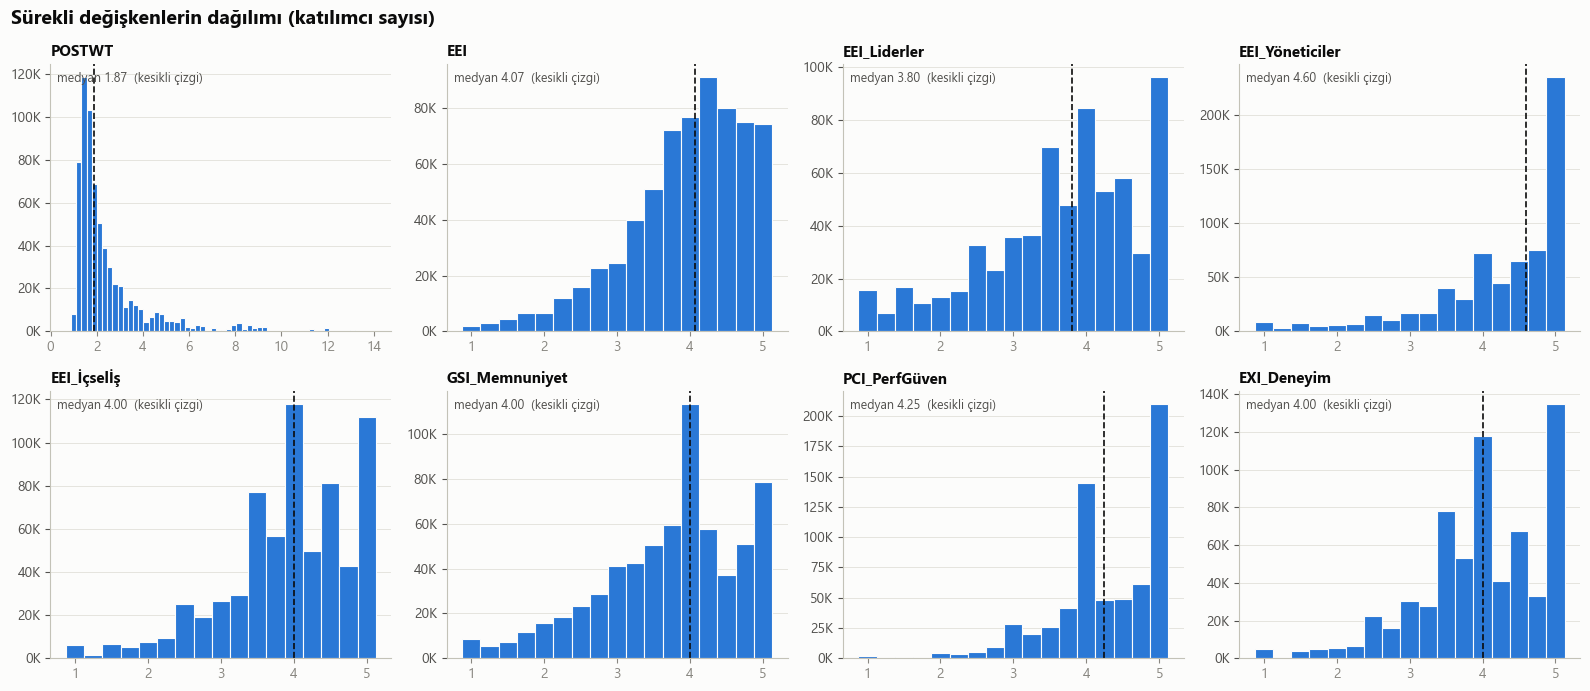

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, CONT_COLS):
    x = df[c].dropna()
    bins = 60 if c == "POSTWT" else np.arange(0.875, 5.2, 0.25)
    ax.hist(x, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
    ax.axvline(x.median(), color=INK, lw=1.2, ls="--")
    ax.text(0.02, 0.97, f"medyan {x.median():.2f}  (kesikli çizgi)", transform=ax.transAxes,
            color=INK2, fontsize=9, va="top")
    ax.set_title(c, fontsize=11)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))
    ax.grid(axis="x", visible=False)
fig.suptitle("Sürekli değişkenlerin dağılımı (katılımcı sayısı)", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
kaydet("02_01_surekli_histogramlar")

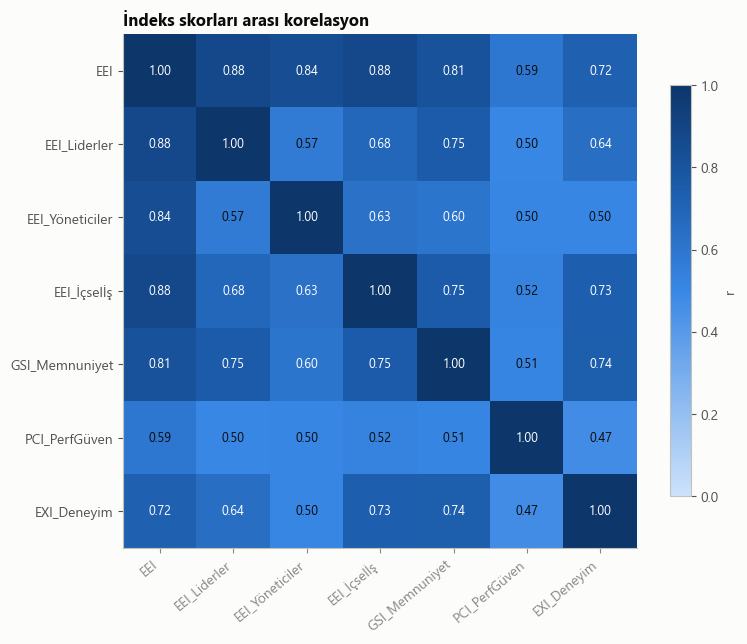

,EEI,EEI_Liderler,EEI_Yöneticiler,EEI_İçselİş,GSI_Memnuniyet,PCI_PerfGüven,EXI_Deneyim
EEI,1.00,0.88,0.84,0.88,0.81,0.59,0.72
EEI_Liderler,0.88,1.00,0.57,0.68,0.75,0.50,0.64
EEI_Yöneticiler,0.84,0.57,1.00,0.63,0.60,0.50,0.50
EEI_İçselİş,0.88,0.68,0.63,1.00,0.75,0.52,0.73
GSI_Memnuniyet,0.81,0.75,0.60,0.75,1.00,0.51,0.74
PCI_PerfGüven,0.59,0.50,0.50,0.52,0.51,1.00,0.47
EXI_Deneyim,0.72,0.64,0.50,0.73,0.74,0.47,1.00


In [8]:
# Korelasyon matrisi (Pearson) – indeks skorları
corr = df[SCORE_COLS].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap=SEQ, vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="r")
ax.set_title("İndeks skorları arası korelasyon")
plt.tight_layout(); kaydet("02_02_korelasyon_matrisi")
corr.round(3)

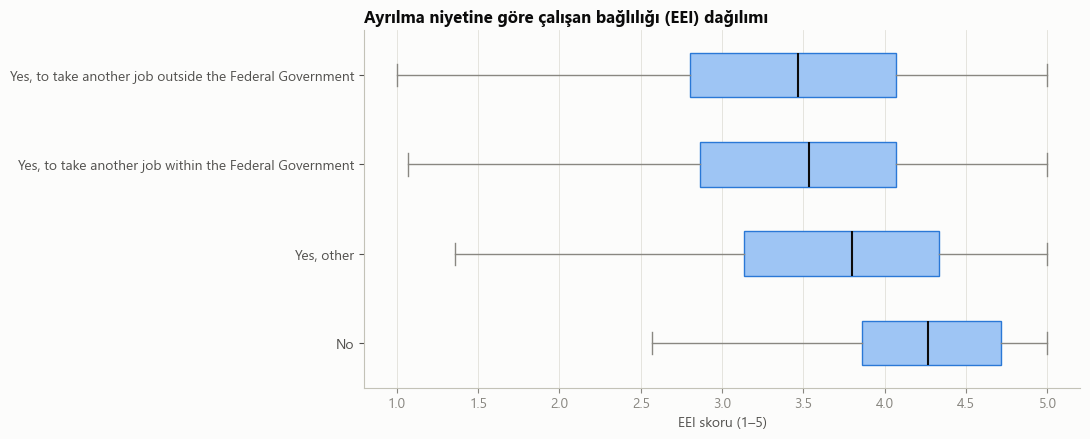

,count,mean,std,min,25%,50%,75%,max
DLEAVING,,,,,,,,
No,"418,339.00",4.18,0.66,1.00,3.86,4.27,4.71,5.00
"Yes, other","75,188.00",3.67,0.90,1.00,3.13,3.80,4.33,5.00
"Yes, to take another job within the Federal Government","114,624.00",3.45,0.89,1.00,2.87,3.53,4.07,5.00
"Yes, to take another job outside the Federal Government","23,993.00",3.39,0.92,1.00,2.80,3.47,4.07,5.00


In [9]:
# Kutu grafiği – ayrılma niyetine göre bağlılık (EEI) skoru
groups = df["DLEAVING"].cat.categories
data = [df.loc[df["DLEAVING"] == g, "EEI"].dropna() for g in groups]
fig, ax = plt.subplots(figsize=(11, 4.5))
bp = ax.boxplot(data, vert=False, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                boxprops=dict(facecolor="#9ec5f4", edgecolor=BLUE))
ax.set_yticks(range(1, len(groups) + 1), groups)
ax.set_xlabel("EEI skoru (1–5)")
ax.set_title("Ayrılma niyetine göre çalışan bağlılığı (EEI) dağılımı")
ax.grid(axis="y", visible=False)
plt.tight_layout(); kaydet("02_03_ayrilma_kutu_grafigi")
df.groupby("DLEAVING", observed=True)["EEI"].describe()

## 3. Nominal ve ikili kategorik değişkenler

In [10]:
def wfreq(col):
    """Frekans tablosu: ağırlıksız sayı + ağırlıklı yüzde (eksikler hariç) + eksik satırı."""
    s, w = df[col], df["POSTWT"]
    t = pd.DataFrame({"n": s.value_counts(sort=False)})
    t["%_ağırlıksız"] = 100 * t["n"] / t["n"].sum()
    t["%_ağırlıklı"] = 100 * w.groupby(s, observed=False).sum() / w[s.notna()].sum()
    t.loc["(Eksik / Maskelenmiş)", "n"] = s.isna().sum()
    t["n"] = t["n"].astype(int)
    t.index.name = col
    return t.round(1)

CAT_COLS = ["Q91"] + DEMO_COLS
freq_tables = {c: wfreq(c) for c in CAT_COLS}
for c, t in freq_tables.items():
    print(f"\n■ {c}: {text_map.get(c, '')}")
    display(t)


■ Q91: Please select the response that BEST describes your current teleworking schedule.


,n,%_ağırlıksız,%_ağırlıklı
Q91,,,
Teleworks frequently or has a remote work agreement,276435,42.70,34.70
Teleworks infrequently; ranging from as-needed up to two days a week,217567,33.60,34.30
"Does not telework; required to be on site, has technical issues, or did not receive approval",127926,19.80,26.70
Chooses not to telework,24819,3.80,4.30
(Eksik / Maskelenmiş),27460,NaN,NaN



■ DRNO: Please select the racial category or categories with which you most closely identify.


,n,%_ağırlıksız,%_ağırlıklı
DRNO,,,
Black or African American,79992,15.00,15.00
White,388927,72.80,72.40
Asian,30768,5.80,5.70
Other Groups Collapsed for Privacy,34477,6.50,6.90
(Eksik / Maskelenmiş),140043,NaN,NaN



■ DHISP: Are you of Hispanic, Latino, or Spanish origin?


...

,n,%_ağırlıksız,%_ağırlıklı
DSEX,,,
Male,269549,51.20,58.50
Female,256446,48.80,41.50
(Eksik / Maskelenmiş),148212,NaN,NaN



■ DMIL: What is your US military service status?


,n,%_ağırlıksız,%_ağırlıklı
DMIL,,,
Military Service,158883,25.30,31.60
No Prior Military Service,469465,74.70,68.40
(Eksik / Maskelenmiş),45859,NaN,NaN



■ DLEAVING: Are you considering leaving your organization within the next year, and if so, why?


,n,%_ağırlıksız,%_ağırlıklı
DLEAVING,,,
No,418426,66.20,63.20
"Yes, other",75213,11.90,12.40
"Yes, to take another job within the Federal Government",114655,18.10,20.30
"Yes, to take another job outside the Federal Government",24004,3.80,4.10
(Eksik / Maskelenmiş),41909,NaN,NaN


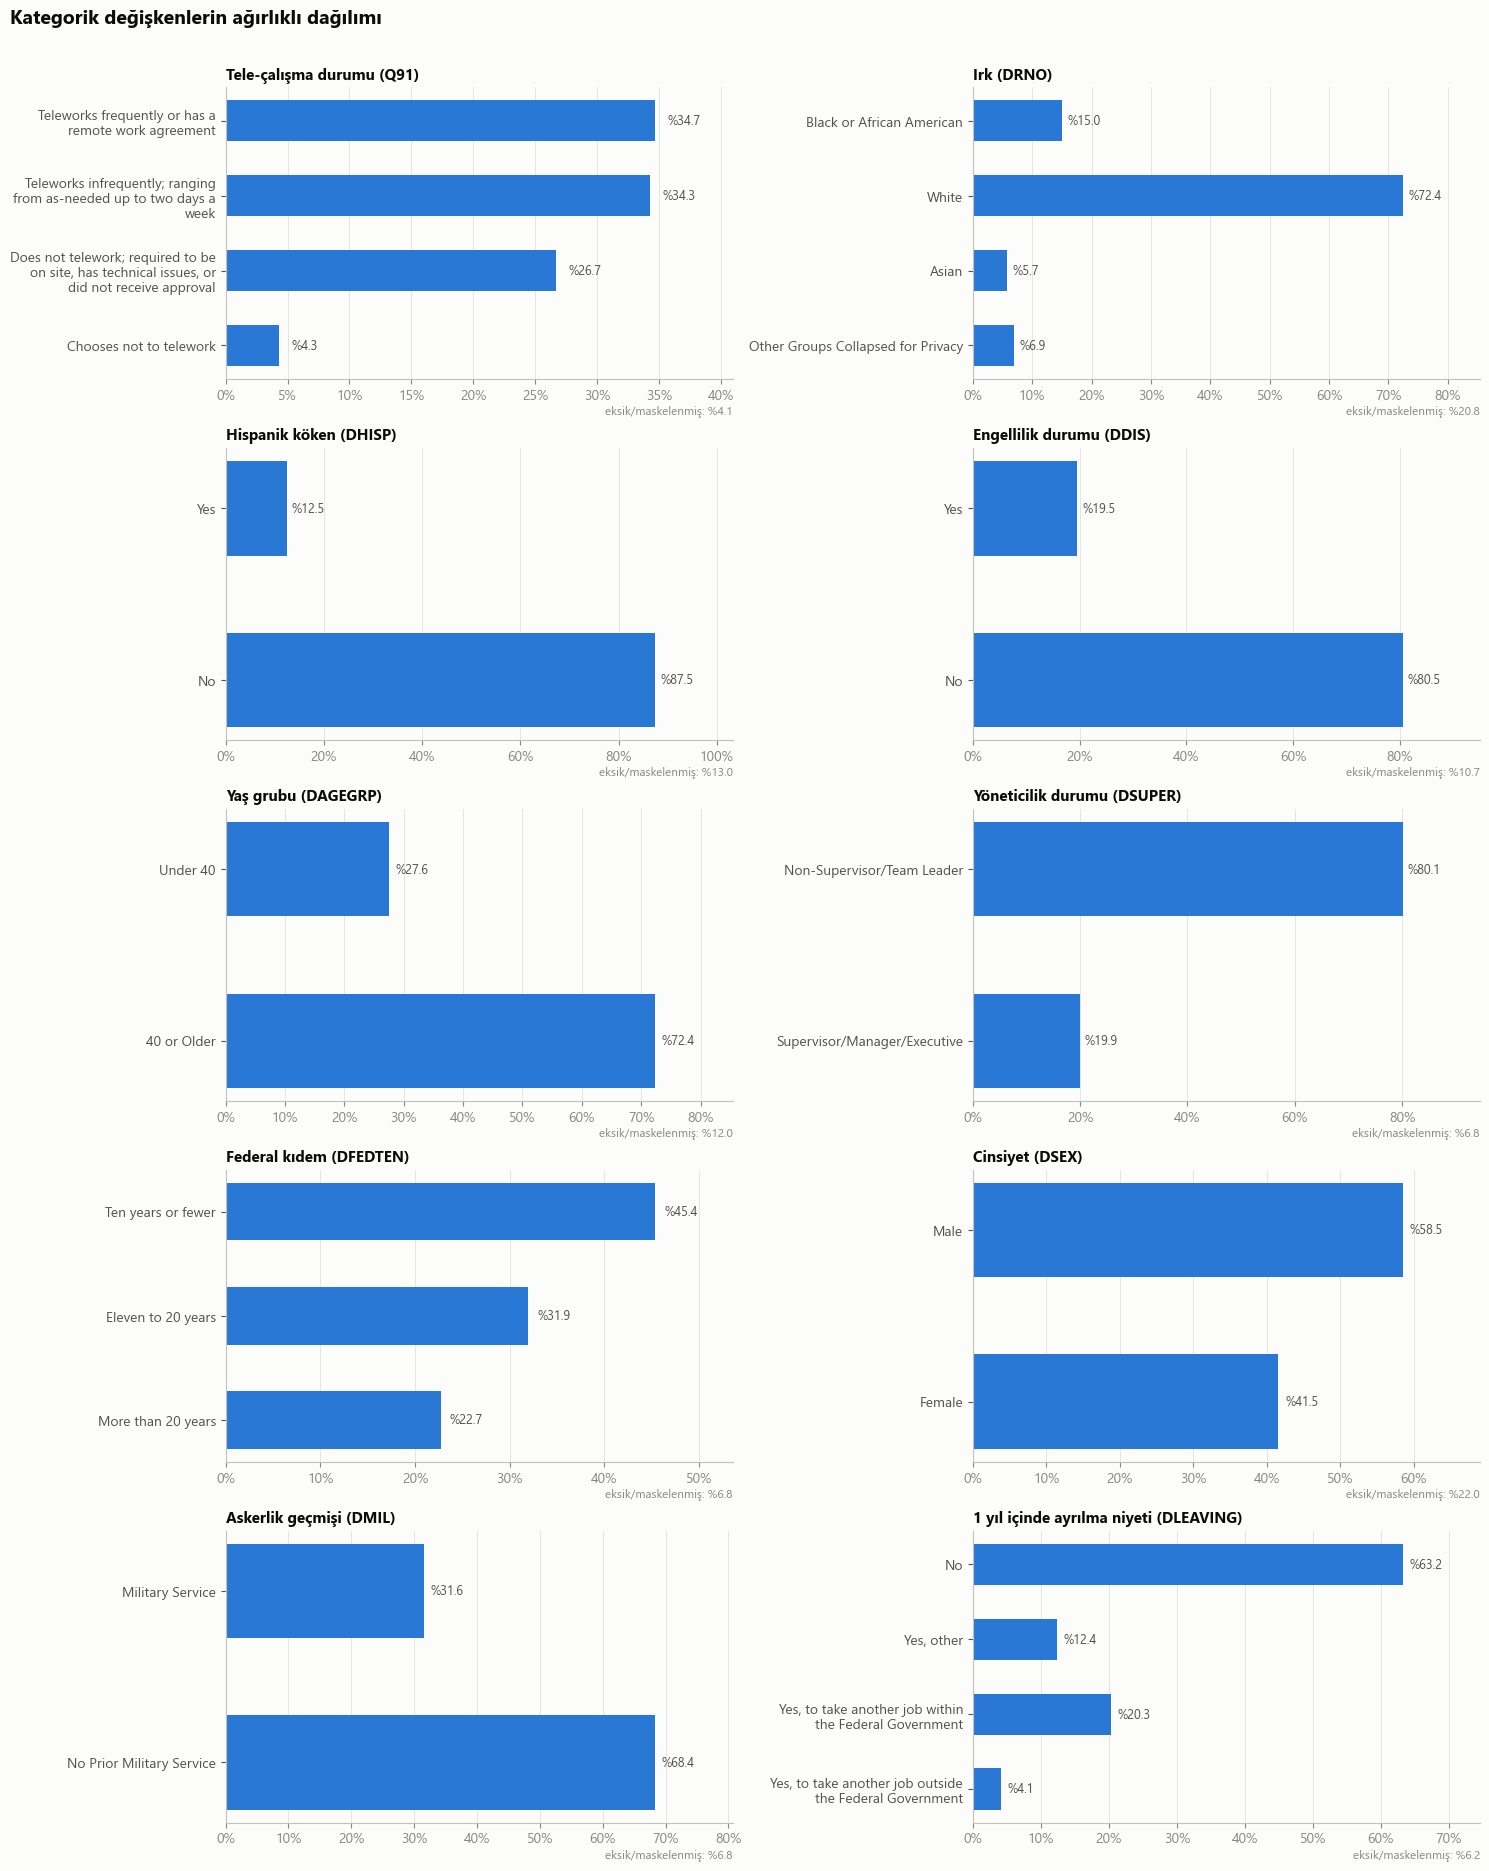

In [11]:
fig, axes = plt.subplots(5, 2, figsize=(15, 19))
for ax, c in zip(axes.flat, CAT_COLS):
    t = freq_tables[c].drop("(Eksik / Maskelenmiş)")["%_ağırlıklı"][::-1]
    labels = [fill(l, 34) for l in t.index.astype(str)]
    ax.barh(labels, t.values, color=BLUE, height=0.55)
    for y, v in enumerate(t.values):
        ax.text(v + 1, y, f"%{v:.1f}", va="center", fontsize=9, color=INK2)
    ax.set_xlim(0, max(t.max() * 1.18, 10))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    miss = freq_tables[c].loc["(Eksik / Maskelenmiş)", "n"] / len(df) * 100
    ax.set_title(f"{TR[c]} ({c})", fontsize=11)
    ax.text(1, -0.12, f"eksik/maskelenmiş: %{miss:.1f}", transform=ax.transAxes, ha="right", fontsize=8.5, color=MUTED)
fig.suptitle("Kategorik değişkenlerin ağırlıklı dağılımı", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.975]); kaydet("02_04_kategorik_dagilimlar")

,seçenek,n_seçen,%_ağırlıklı
VARIABLE,,,
Q16_1,Remain in the work unit and improve their perf...,123868,18.30
Q16_2,Remain in the work unit and continue to underp...,250484,40.00
Q16_3,Leave the work unit - removed or transferred,65515,10.40
Q16_4,Leave the work unit - quit,41652,6.40
Q16_5,There are no poor performers in my work unit,139634,19.70
Q16_6,Do Not Know,147845,20.60


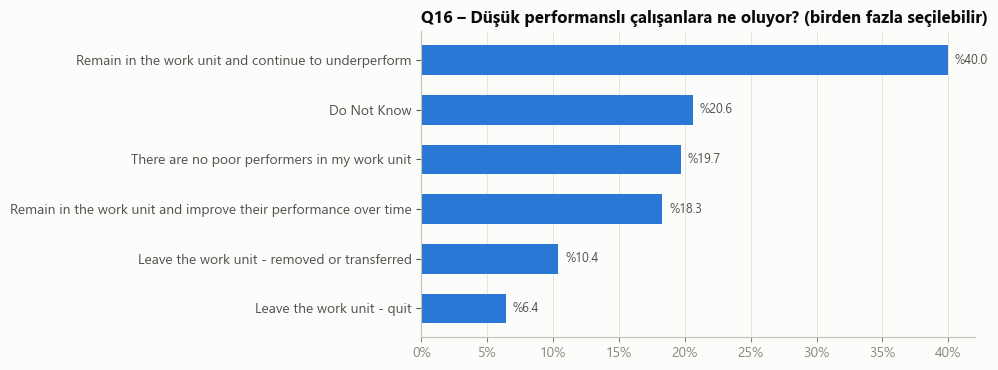

In [12]:
# Q16 – Çoklu seçim: "Çalışma birimimde düşük performanslılar genellikle…"
q16_labels = items.loc[items["VARIABLE"].isin(Q16_COLS)].set_index("VARIABLE")["RESPONSE CHOICES"].str.strip()
q16 = pd.DataFrame({
    "seçenek": q16_labels,
    "n_seçen": [int(df[c].sum()) for c in Q16_COLS],
    "%_ağırlıklı": [100 * wmean(df[c].astype(float), df["POSTWT"]) for c in Q16_COLS],
}).round(1)
display(q16)

fig, ax = plt.subplots(figsize=(10, 3.8))
t = q16.sort_values("%_ağırlıklı")
ax.barh(t["seçenek"], t["%_ağırlıklı"], color=BLUE, height=0.6)
for y, v in enumerate(t["%_ağırlıklı"]):
    ax.text(v + 0.5, y, f"%{v:.1f}", va="center", fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis="y", visible=False)
ax.set_title("Q16 – Düşük performanslı çalışanlara ne oluyor? (birden fazla seçilebilir)")
plt.tight_layout(); kaydet("02_05_Q16_dusuk_performans")

,katılımcı,temsil_edilen,%_katılımcı
agency_name,,,
Department of Homeland Security,94177,"215,227.50",14.00
United States Department of the Army,61640,"219,685.00",9.10
Department of Health and Human Services,59261,"84,001.10",8.80
Department of Agriculture,50695,"92,459.10",7.50
Department of the Treasury,49794,"101,044.80",7.40
United States Department of the Navy,47116,"193,668.40",7.00
"OSD, Joint Staff, Defense Agencies, and Field Activities",44115,"148,977.90",6.50
Social Security Administration,40016,"57,795.30",5.90
Department of Justice,38897,"113,240.20",5.80


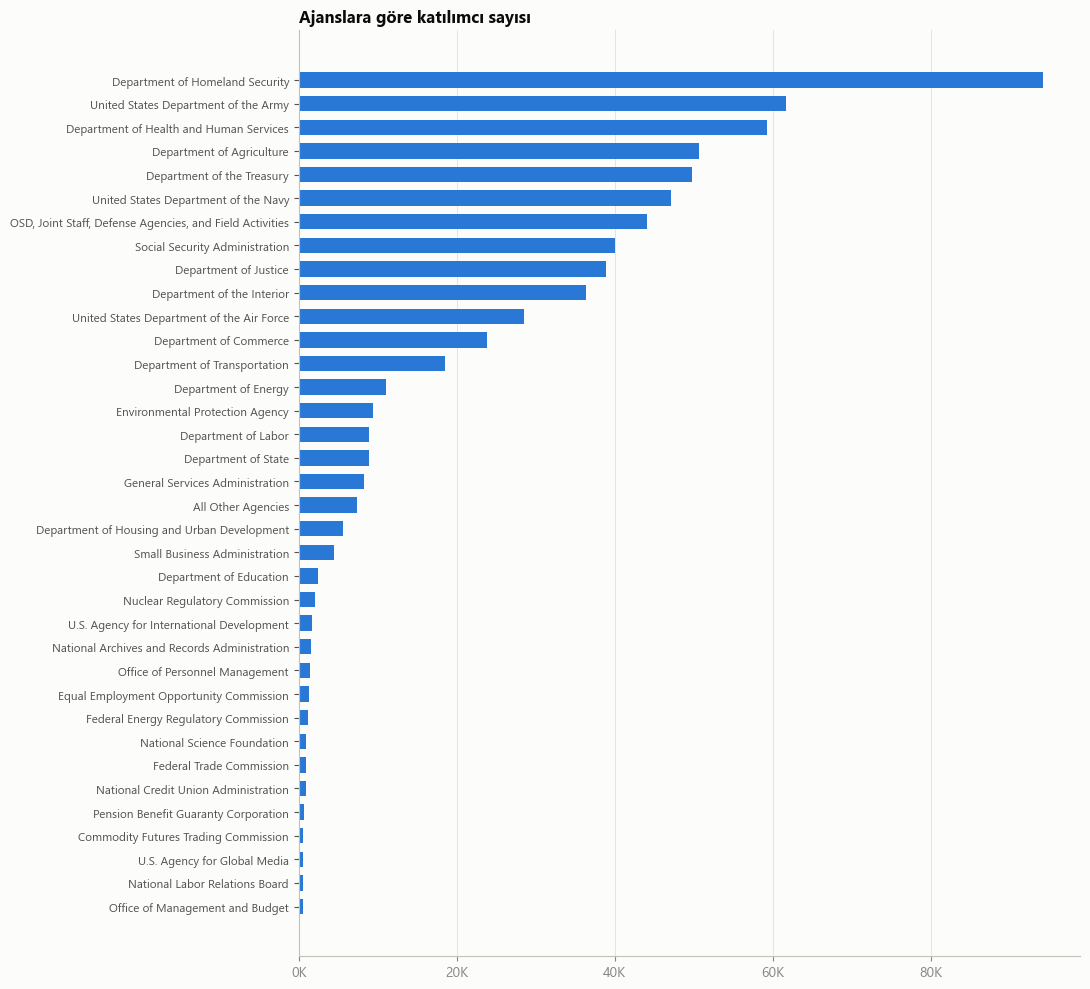

In [13]:
# Ajans dağılımı
ag = df.groupby("agency_name", observed=True).agg(katılımcı=("POSTWT", "size"), temsil_edilen=("POSTWT", "sum"))
ag["%_katılımcı"] = 100 * ag["katılımcı"] / ag["katılımcı"].sum()
ag = ag.sort_values("katılımcı", ascending=False).round(1)
display(ag)

fig, ax = plt.subplots(figsize=(11, 10))
t = ag["katılımcı"][::-1]
ax.barh(t.index, t.values, color=BLUE, height=0.65)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("Ajanslara göre katılımcı sayısı")
plt.tight_layout(); kaydet("02_06_ajans_katilimci")

## 4. Sıralı kategorik değişkenler – Likert maddeleri (Q1–Q90)
- **Pozitif:** 4–5 (Katılıyorum / Kesinlikle katılıyorum, Memnun / Çok memnun, İyi / Çok iyi)
- **Nötr:** 3
- **Negatif:** 1–2

In [14]:
def pnn(col):
    m = df[col].notna(); x = df.loc[m, col]; w = df.loc[m, "POSTWT"]; tot = w.sum()
    return pd.Series({"Pozitif": 100 * w[x >= 4].sum() / tot, "Nötr": 100 * w[x == 3].sum() / tot,
                      "Negatif": 100 * w[x <= 2].sum() / tot, "Ort (1–5)": np.average(x, weights=w),
                      "n_geçerli": int(m.sum())})

likert = pd.DataFrame({c: pnn(c) for c in LIKERT_COLS}).T
likert["n_geçerli"] = likert["n_geçerli"].astype(int)
dim = items.groupby("VARIABLE")[["INDEX", "PERFORMANCE DIMENSION"]].first()
likert["indeks/boyut"] = (dim["INDEX"].fillna(dim["PERFORMANCE DIMENSION"])
                          .str.replace("Performance Dimension: ", "", regex=False)).reindex(likert.index)
likert["madde"] = [text_map[c] for c in likert.index]
likert.round(1)

,Pozitif,Nötr,Negatif,Ort (1–5),n_geçerli,indeks/boyut,madde
Q1,72.20,13.90,13.90,3.80,670623,Employee-Focused - Employee Development,I am given a real opportunity to improve my sk...
Q2,67.10,15.40,17.50,3.70,664020,Employee Engagement Index - Intrinsic Work Exp...,I feel encouraged to come up with new and bett...
Q3,74.20,13.80,12.00,3.90,664559,Employee Engagement Index - Intrinsic Work Exp...,My work gives me a feeling of personal accompl...
Q4,82.30,9.70,8.00,4.10,663290,Employee Engagement Index - Intrinsic Work Exp...,I know what is expected of me on the job.
Q5,63.30,14.60,22.00,3.50,669177,Employee-Focused - Work-Life Support,My workload is reasonable.
Q6,65.50,16.20,18.30,3.70,662558,Employee Engagement Index - Intrinsic Work Exp...,My talents are used well in the workplace.
Q7,85.60,8.70,5.70,4.20,668952,Employee Engagement Index - Intrinsic Work Exp...,I know how my work relates to the agency's goals.
Q8,71.90,13.90,14.20,3.90,644414,Foundations - Merit Principles,I can disclose a suspected violation of any la...
Q9,73.90,13.80,12.30,3.80,671755,Foundations - Performance Resources,I have enough information to do my job well.
Q10,66.70,17.30,16.00,3.70,666259,Employee-Focused - Employee Development,I receive the training I need to do my job well.


In [15]:
# Her maddenin 1–5 dağılımı (ağırlıklı %)
dist = pd.DataFrame({c: df.groupby(c, observed=True)["POSTWT"].sum() for c in LIKERT_COLS}).T
dist = (dist.div(dist.sum(axis=1), axis=0) * 100).round(1)
dist.columns = [f"{int(k)}" for k in dist.columns]
dist

,1,2,3,4,5
Q1,4.50,9.40,13.90,42.50,29.70
Q2,6.20,11.30,15.40,37.70,29.40
Q3,4.50,7.50,13.80,41.70,32.50
Q4,2.70,5.30,9.70,46.60,35.60
Q5,8.60,13.40,14.60,42.00,21.30
Q6,7.00,11.30,16.20,40.60,24.90
Q7,2.40,3.30,8.70,46.30,39.30
Q8,6.80,7.40,13.90,34.70,37.30
Q9,3.00,9.30,13.80,50.50,23.40
Q10,4.50,11.50,17.30,43.70,23.00


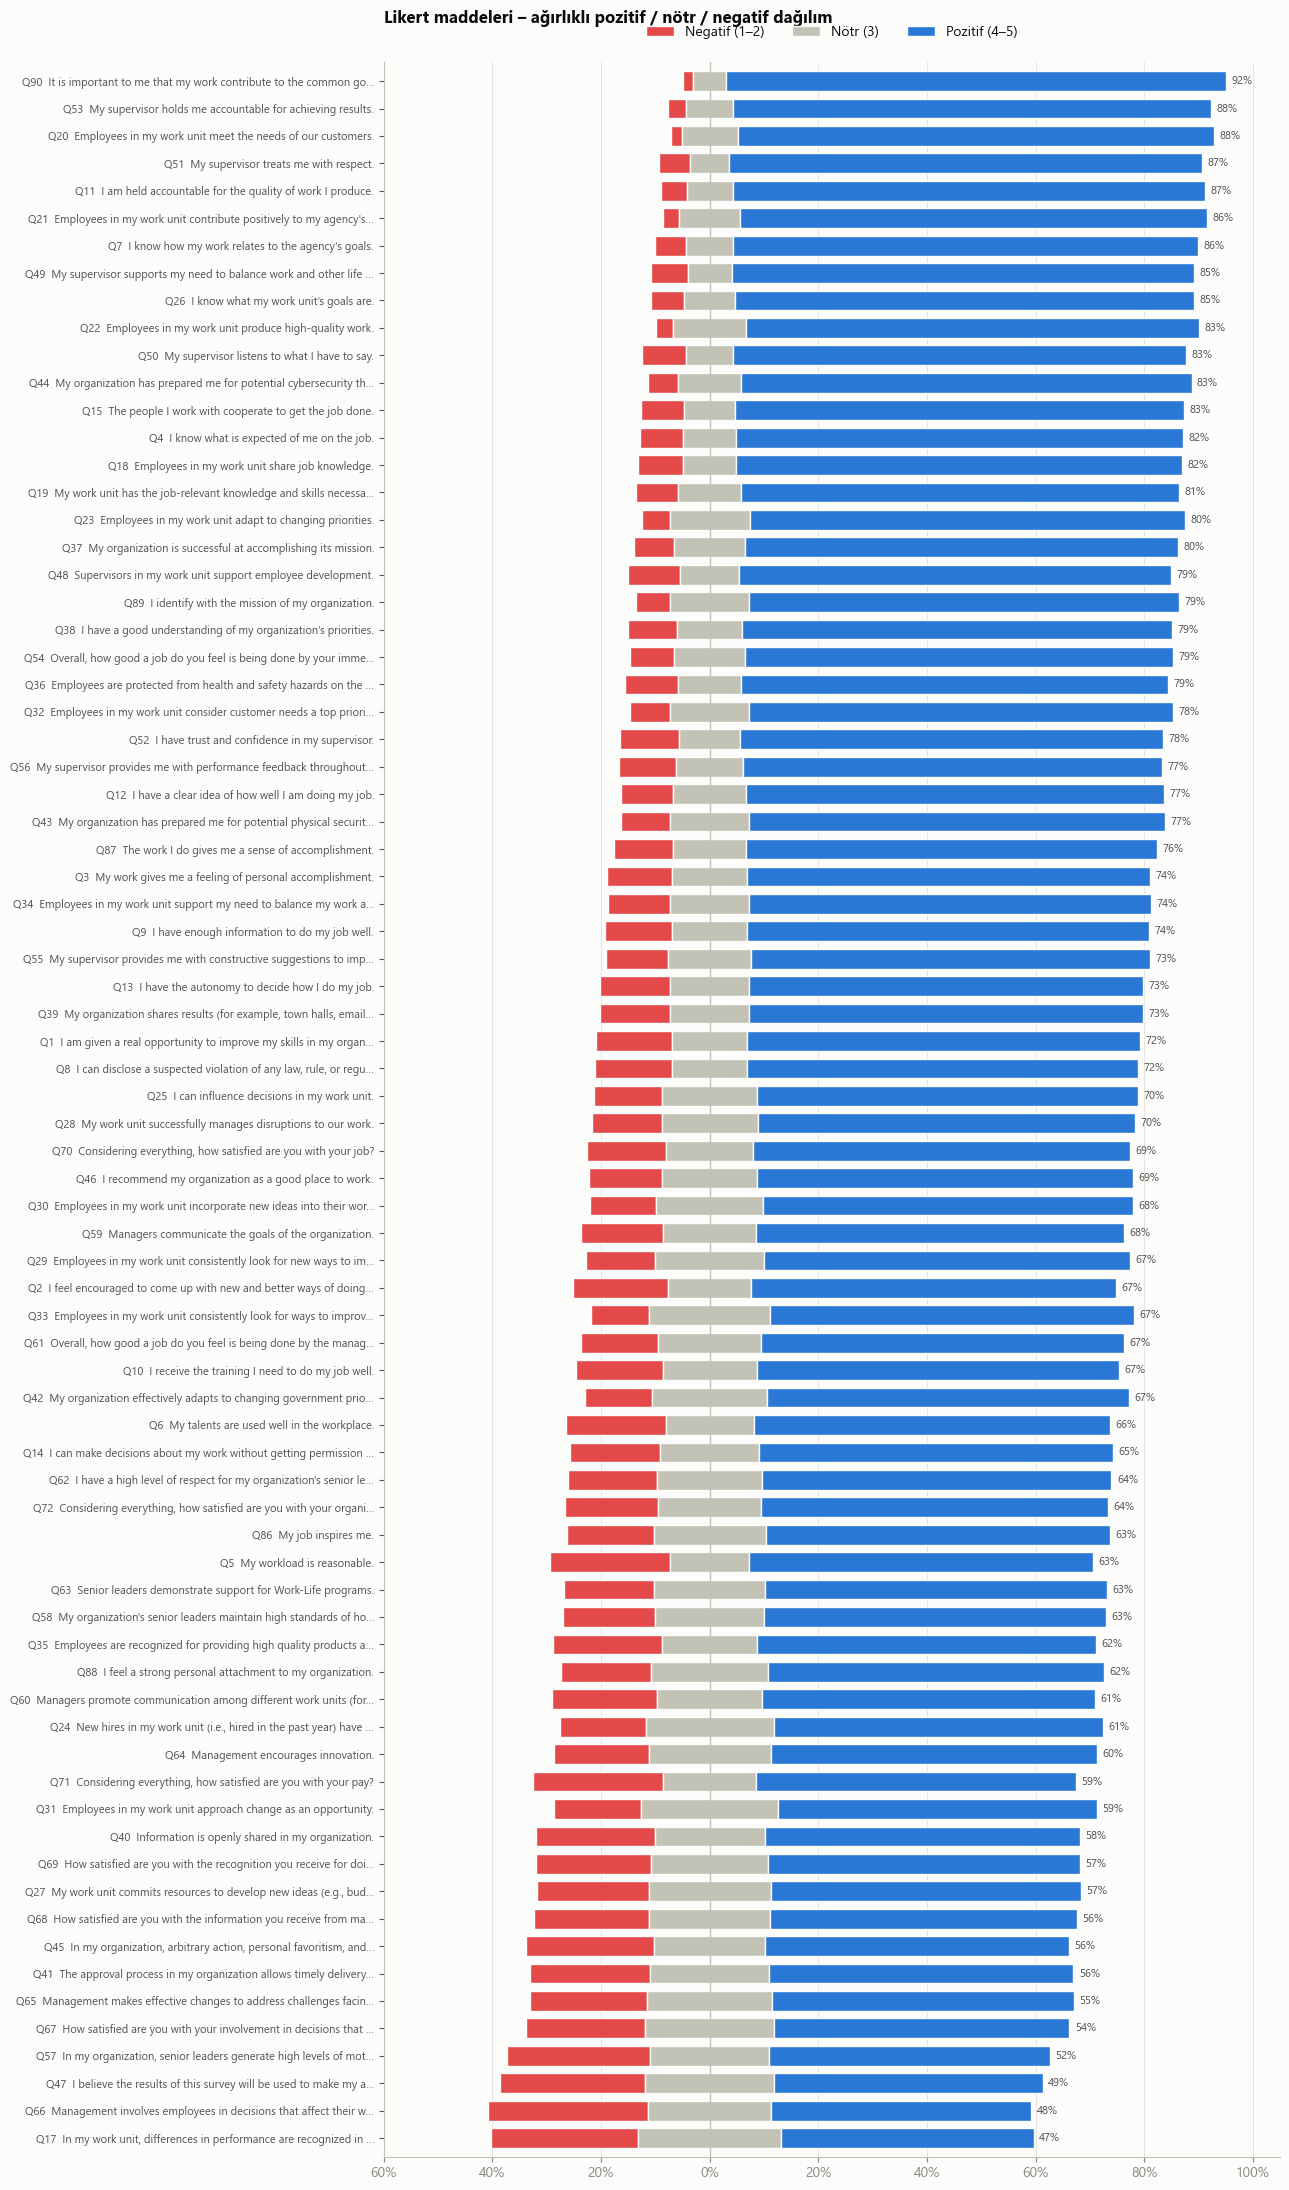

In [16]:
# Iraksak yığılmış çubuk grafiği – 76 madde, pozitife göre sıralı
t = likert.sort_values("Pozitif")
fig, ax = plt.subplots(figsize=(13, 22))
y = np.arange(len(t))
ax.barh(y, -t["Negatif"], left=-t["Nötr"] / 2, color=NEG, height=0.72, label="Negatif (1–2)", edgecolor=SURFACE, linewidth=1)
ax.barh(y, t["Nötr"], left=-t["Nötr"] / 2, color=NEU, height=0.72, label="Nötr (3)", edgecolor=SURFACE, linewidth=1)
ax.barh(y, t["Pozitif"], left=t["Nötr"] / 2, color=POS, height=0.72, label="Pozitif (4–5)", edgecolor=SURFACE, linewidth=1)
for yi, (q, row) in enumerate(t.iterrows()):
    ax.text(row["Pozitif"] + row["Nötr"] / 2 + 1, yi, f"{row['Pozitif']:.0f}%", va="center", fontsize=8, color=INK2)
lab = [f"{q}  {text_map[q][:62]}{'…' if len(text_map[q]) > 62 else ''}" for q in t.index]
ax.set_yticks(y, lab, fontsize=8)
ax.set_ylim(-0.7, len(t) - 0.3)
ax.axvline(0, color=AXIS, lw=1)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{abs(v):.0f}%"))
ax.set_xlim(-60, 105); ax.grid(axis="y", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.005), frameon=False, ncol=3)
ax.set_title("Likert maddeleri – ağırlıklı pozitif / nötr / negatif dağılım", pad=28)
plt.tight_layout(); kaydet("02_07_likert_76_madde")

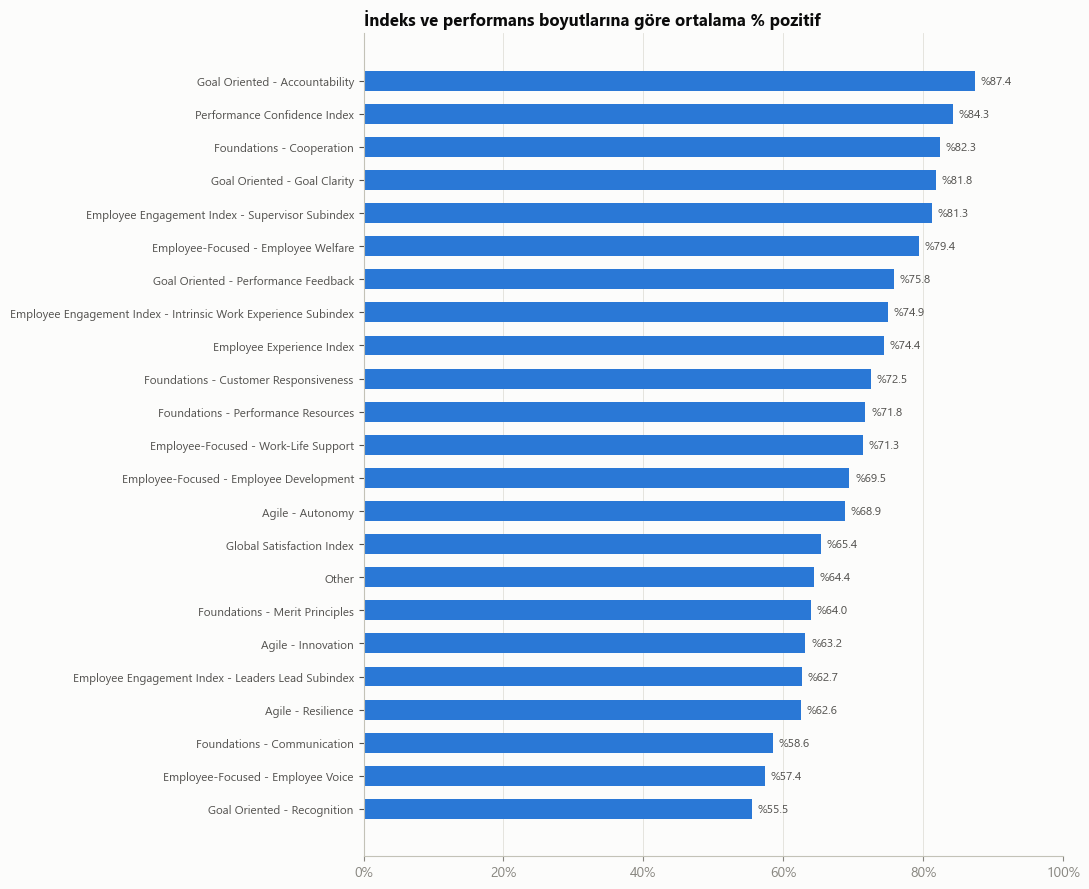

,ort_%_pozitif,madde_sayısı
indeks/boyut,,
Goal Oriented - Recognition,55.50,3
Employee-Focused - Employee Voice,57.40,3
Foundations - Communication,58.60,3
Agile - Resilience,62.60,4
Employee Engagement Index - Leaders Lead Subindex,62.70,5
Agile - Innovation,63.20,4
Foundations - Merit Principles,64.00,2
Other,64.40,4
Global Satisfaction Index,65.40,4


In [17]:
# Boyut / indeks bazında ortalama % pozitif
grp = likert.groupby("indeks/boyut")["Pozitif"].agg(["mean", "count"]).sort_values("mean")
grp.columns = ["ort_%_pozitif", "madde_sayısı"]
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(grp.index, grp["ort_%_pozitif"], color=BLUE, height=0.6)
for yi, v in enumerate(grp["ort_%_pozitif"]):
    ax.text(v + 0.8, yi, f"%{v:.1f}", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("İndeks ve performans boyutlarına göre ortalama % pozitif")
plt.tight_layout(); kaydet("02_08_boyut_bazinda_pozitif")
grp.round(1)

## 5. Çapraz analizler
OPM yöntemiyle (% pozitif ortalaması) resmi indeks skorlarının demografik kırılımları.

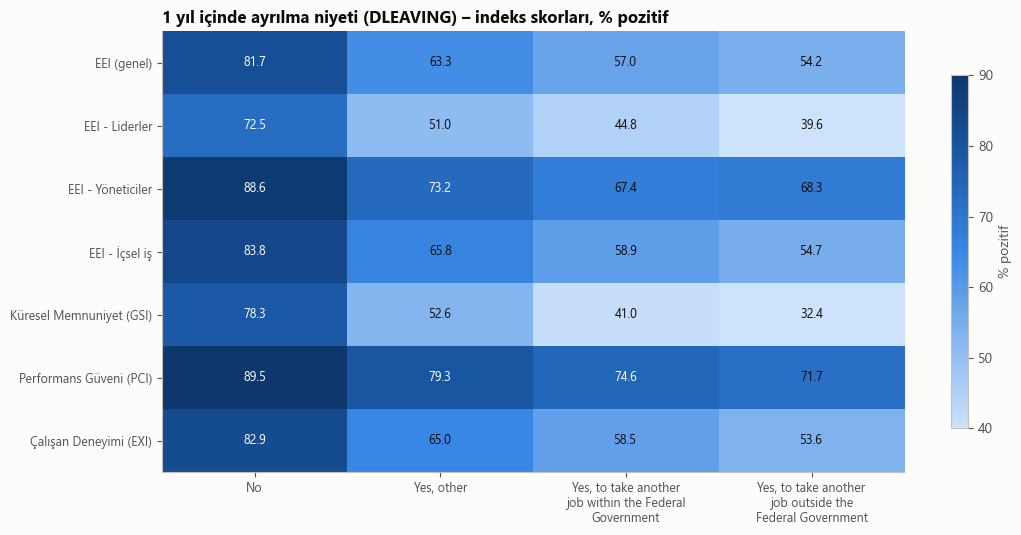

DLEAVING,No,"Yes, other","Yes, to take another job within the Federal Government","Yes, to take another job outside the Federal Government"
EEI (genel),81.70,63.30,57.00,54.20
EEI - Liderler,72.50,51.00,44.80,39.60
EEI - Yöneticiler,88.60,73.20,67.40,68.30
EEI - İçsel iş,83.80,65.80,58.90,54.70
Küresel Memnuniyet (GSI),78.30,52.60,41.00,32.40
Performans Güveni (PCI),89.50,79.30,74.60,71.70
Çalışan Deneyimi (EXI),82.90,65.00,58.50,53.60


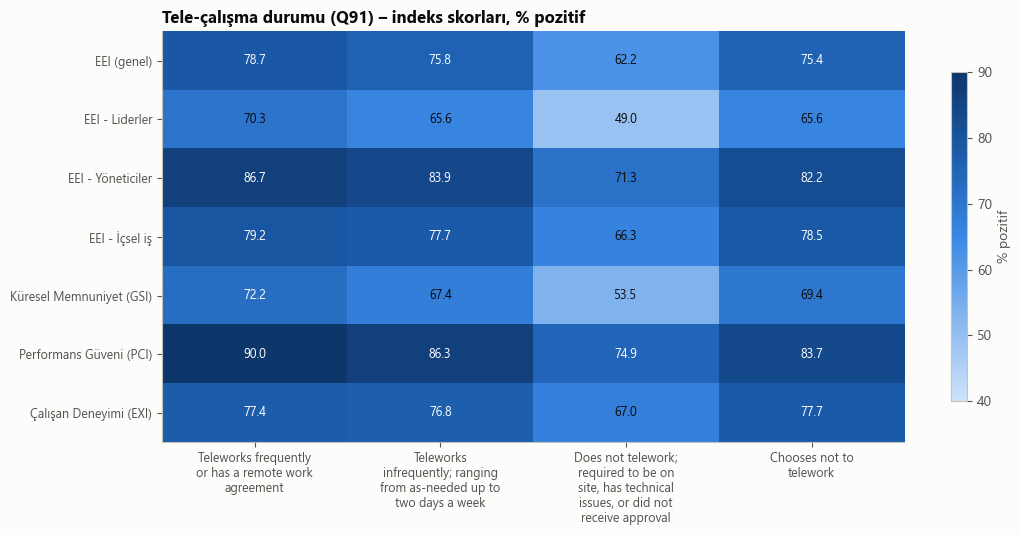

Q91,Teleworks frequently or has a remote work agreement,Teleworks infrequently; ranging from as-needed up to two days a week,"Does not telework; required to be on site, has technical issues, or did not receive approval",Chooses not to telework
EEI (genel),78.70,75.80,62.20,75.40
EEI - Liderler,70.30,65.60,49.00,65.60
EEI - Yöneticiler,86.70,83.90,71.30,82.20
EEI - İçsel iş,79.20,77.70,66.30,78.50
Küresel Memnuniyet (GSI),72.20,67.40,53.50,69.40
Performans Güveni (PCI),90.00,86.30,74.90,83.70
Çalışan Deneyimi (EXI),77.40,76.80,67.00,77.70


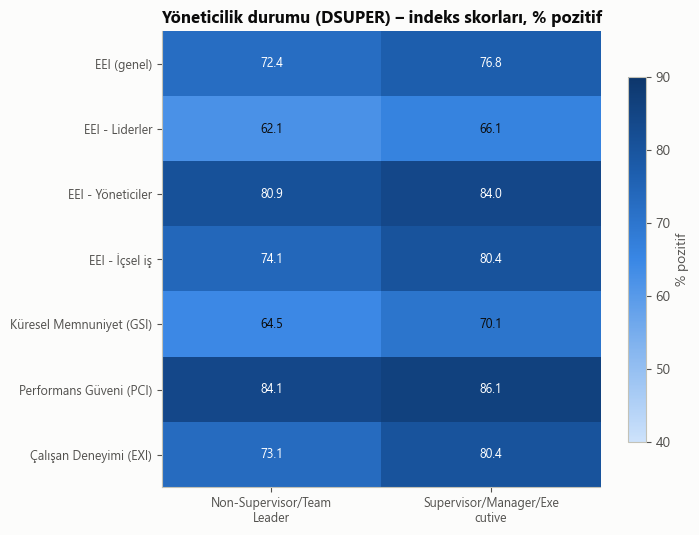

DSUPER,Non-Supervisor/Team Leader,Supervisor/Manager/Executive
EEI (genel),72.40,76.80
EEI - Liderler,62.10,66.10
EEI - Yöneticiler,80.90,84.00
EEI - İçsel iş,74.10,80.40
Küresel Memnuniyet (GSI),64.50,70.10
Performans Güveni (PCI),84.10,86.10
Çalışan Deneyimi (EXI),73.10,80.40


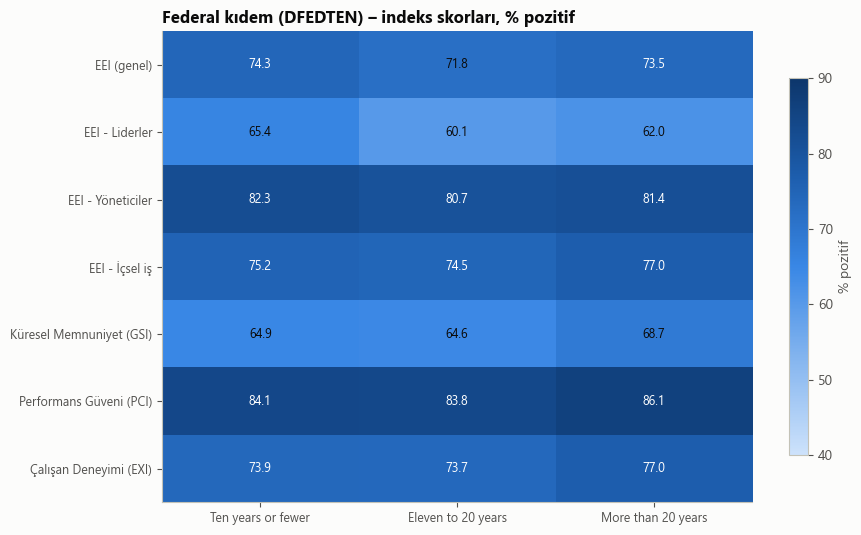

DFEDTEN,Ten years or fewer,Eleven to 20 years,More than 20 years
EEI (genel),74.30,71.80,73.50
EEI - Liderler,65.40,60.10,62.00
EEI - Yöneticiler,82.30,80.70,81.40
EEI - İçsel iş,75.20,74.50,77.00
Küresel Memnuniyet (GSI),64.90,64.60,68.70
Performans Güveni (PCI),84.10,83.80,86.10
Çalışan Deneyimi (EXI),73.90,73.70,77.00


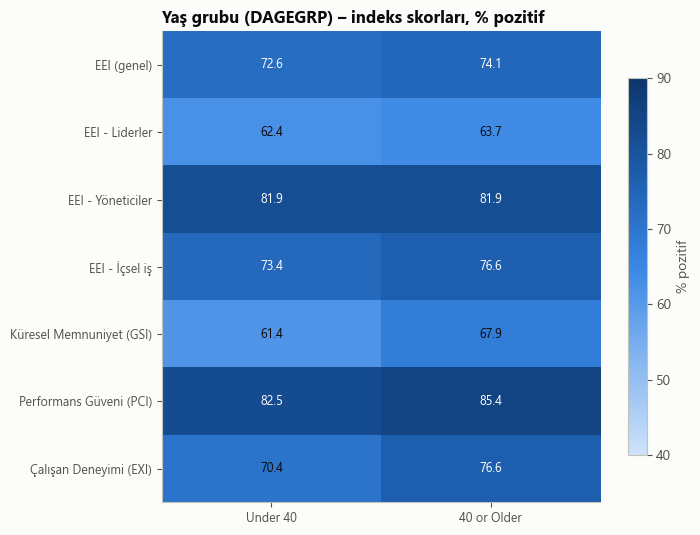

DAGEGRP,Under 40,40 or Older
EEI (genel),72.60,74.10
EEI - Liderler,62.40,63.70
EEI - Yöneticiler,81.90,81.90
EEI - İçsel iş,73.40,76.60
Küresel Memnuniyet (GSI),61.40,67.90
Performans Güveni (PCI),82.50,85.40
Çalışan Deneyimi (EXI),70.40,76.60


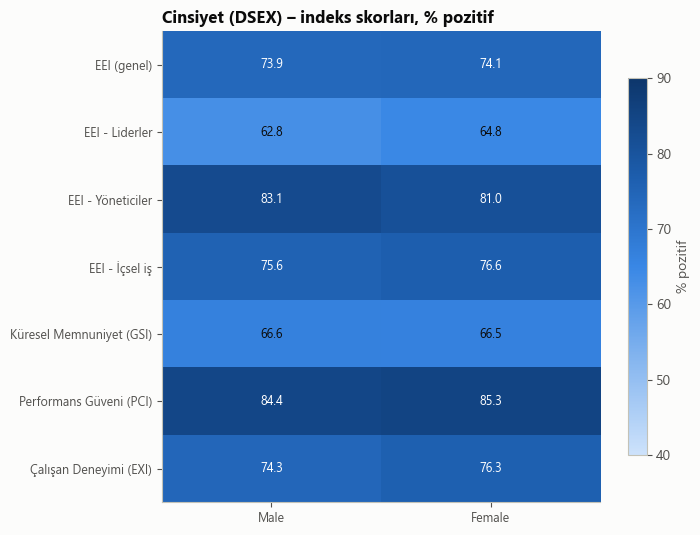

DSEX,Male,Female
EEI (genel),73.90,74.10
EEI - Liderler,62.80,64.80
EEI - Yöneticiler,83.10,81.00
EEI - İçsel iş,75.60,76.60
Küresel Memnuniyet (GSI),66.60,66.50
Performans Güveni (PCI),84.40,85.30
Çalışan Deneyimi (EXI),74.30,76.30


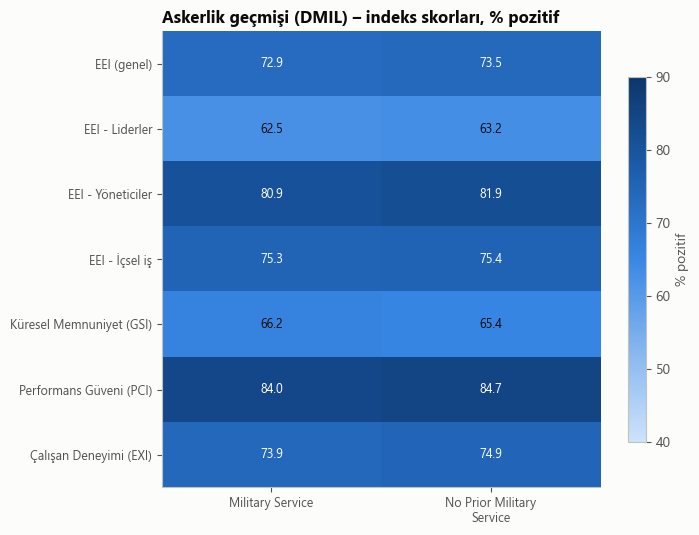

DMIL,Military Service,No Prior Military Service
EEI (genel),72.90,73.50
EEI - Liderler,62.50,63.20
EEI - Yöneticiler,80.90,81.90
EEI - İçsel iş,75.30,75.40
Küresel Memnuniyet (GSI),66.20,65.40
Performans Güveni (PCI),84.00,84.70
Çalışan Deneyimi (EXI),73.90,74.90


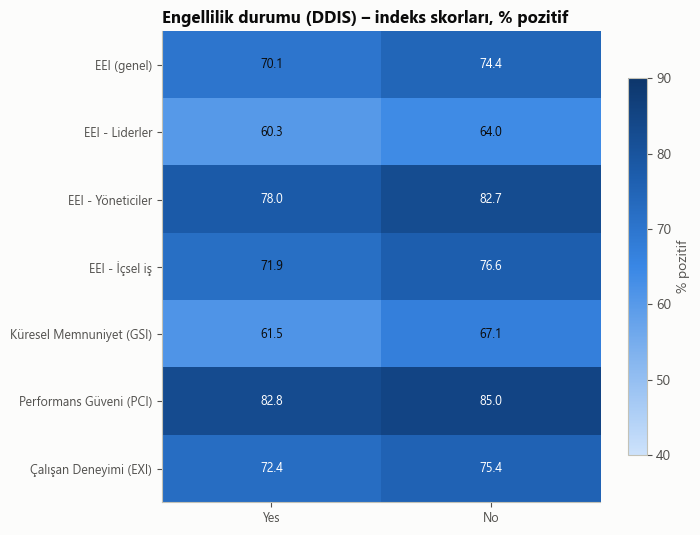

DDIS,Yes,No
EEI (genel),70.10,74.40
EEI - Liderler,60.30,64.00
EEI - Yöneticiler,78.00,82.70
EEI - İçsel iş,71.90,76.60
Küresel Memnuniyet (GSI),61.50,67.10
Performans Güveni (PCI),82.80,85.00
Çalışan Deneyimi (EXI),72.40,75.40


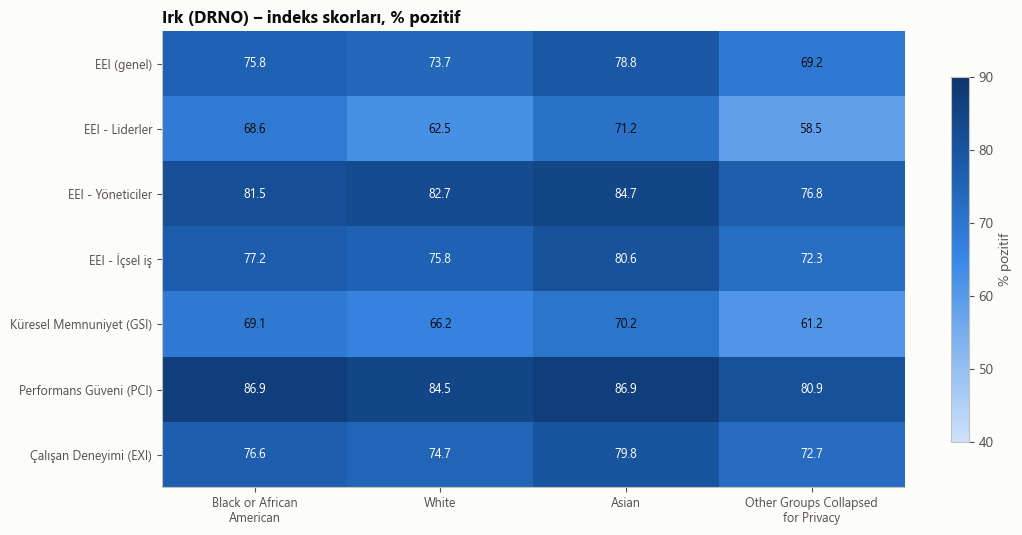

DRNO,Black or African American,White,Asian,Other Groups Collapsed for Privacy
EEI (genel),75.80,73.70,78.80,69.20
EEI - Liderler,68.60,62.50,71.20,58.50
EEI - Yöneticiler,81.50,82.70,84.70,76.80
EEI - İçsel iş,77.20,75.80,80.60,72.30
Küresel Memnuniyet (GSI),69.10,66.20,70.20,61.20
Performans Güveni (PCI),86.90,84.50,86.90,80.90
Çalışan Deneyimi (EXI),76.60,74.70,79.80,72.70


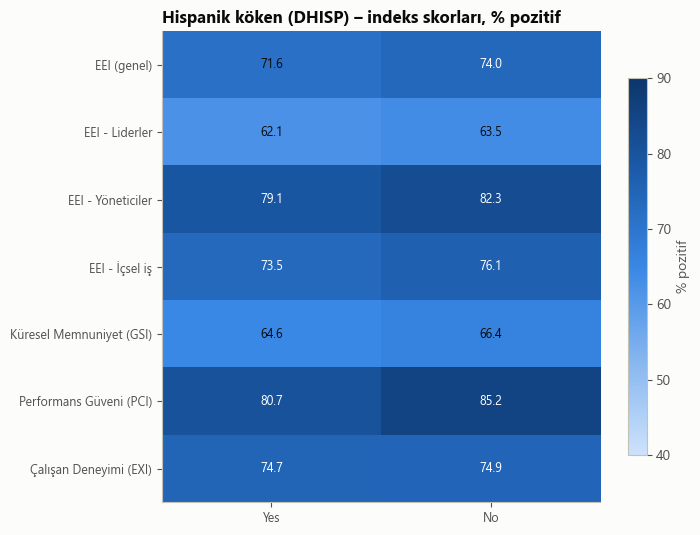

DHISP,Yes,No
EEI (genel),71.60,74.00
EEI - Liderler,62.10,63.50
EEI - Yöneticiler,79.10,82.30
EEI - İçsel iş,73.50,76.10
Küresel Memnuniyet (GSI),64.60,66.40
Performans Güveni (PCI),80.70,85.20
Çalışan Deneyimi (EXI),74.70,74.90


In [18]:
OPM_INDICES = {
    "EEI - Liderler": INDICES["EEI_Liderler"], "EEI - Yöneticiler": INDICES["EEI_Yöneticiler"],
    "EEI - İçsel iş": INDICES["EEI_İçselİş"], "Küresel Memnuniyet (GSI)": INDICES["GSI_Memnuniyet"],
    "Performans Güveni (PCI)": INDICES["PCI_PerfGüven"], "Çalışan Deneyimi (EXI)": INDICES["EXI_Deneyim"],
}
POS_FLAGS = {q: (df[q] >= 4).astype(float).where(df[q].notna()) for q in LIKERT_COLS}

def pct_pos_by(group_col, q):
    v = POS_FLAGS[q]; m = v.notna() & df[group_col].notna()
    wv = (v[m] * df.loc[m, "POSTWT"]).groupby(df.loc[m, group_col], observed=True).sum()
    return 100 * wv / df.loc[m, "POSTWT"].groupby(df.loc[m, group_col], observed=True).sum()

def index_by(group_col):
    out = {k: pd.concat([pct_pos_by(group_col, q) for q in qs], axis=1).mean(axis=1) for k, qs in OPM_INDICES.items()}
    out = pd.DataFrame(out)
    out.insert(0, "EEI (genel)", out[["EEI - Liderler", "EEI - Yöneticiler", "EEI - İçsel iş"]].mean(axis=1))
    return out.T

def heat(tab, title, ad):
    fig, ax = plt.subplots(figsize=(1.9 * tab.shape[1] + 3.5, 0.55 * tab.shape[0] + 1.6))
    im = ax.imshow(tab.values, cmap=SEQ, vmin=40, vmax=90, aspect="auto")
    ax.set_xticks(range(tab.shape[1]), [fill(str(c), 22) for c in tab.columns], fontsize=9)
    ax.tick_params(axis="x", colors=INK2)
    ax.set_yticks(range(tab.shape[0]), tab.index, fontsize=9); ax.grid(False)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.iat[i, j]
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9, color="white" if v > 72 else INK)
    fig.colorbar(im, ax=ax, shrink=0.8, label="% pozitif")
    ax.set_title(title); plt.tight_layout(); kaydet(ad)

cross_tables = {}
for c in ["DLEAVING", "Q91", "DSUPER", "DFEDTEN", "DAGEGRP", "DSEX", "DMIL", "DDIS", "DRNO", "DHISP"]:
    tab = index_by(c)
    cross_tables[c] = tab.round(1)
    heat(tab, f"{TR[c]} ({c}) – indeks skorları, % pozitif", f"02_09_capraz_{c}")
    display(tab.round(1))

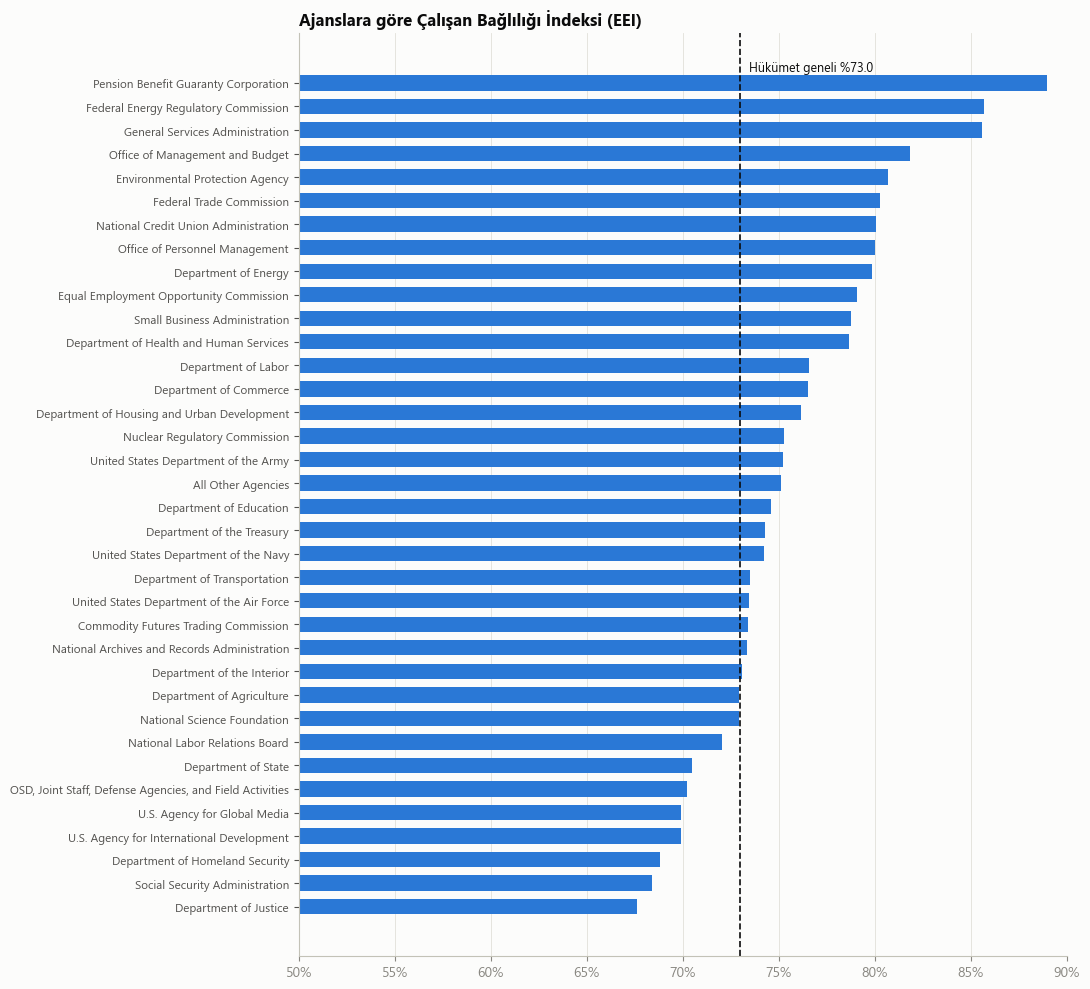

,EEI (genel),EEI - Liderler,EEI - Yöneticiler,EEI - İçsel iş,Küresel Memnuniyet (GSI),Performans Güveni (PCI),Çalışan Deneyimi (EXI)
agency_name,,,,,,,
Pension Benefit Guaranty Corporation,89.00,84.10,93.00,89.80,87.40,97.00,86.50
Federal Energy Regulatory Commission,85.70,82.30,91.80,83.00,79.90,92.70,80.80
General Services Administration,85.60,80.80,91.30,84.70,82.10,93.90,81.30
Office of Management and Budget,81.90,75.10,87.10,83.40,77.60,91.90,86.70
Environmental Protection Agency,80.70,72.70,88.00,81.50,77.30,91.20,83.70
Federal Trade Commission,80.30,65.70,91.00,84.00,68.50,95.70,86.00
National Credit Union Administration,80.00,73.70,86.10,80.40,76.40,91.10,79.00
Office of Personnel Management,80.00,73.50,87.30,79.20,74.90,90.60,79.20
Department of Energy,79.80,70.60,87.60,81.30,74.80,91.80,79.40


In [19]:
# Ajanslara göre Çalışan Bağlılığı (EEI) skoru
ag_idx = index_by("agency_name").T.sort_values("EEI (genel)")
gov_eei = np.mean([np.mean([100 * wmean(POS_FLAGS[q], df["POSTWT"]) for q in OPM_INDICES[k]])
                   for k in ["EEI - Liderler", "EEI - Yöneticiler", "EEI - İçsel iş"]])
fig, ax = plt.subplots(figsize=(11, 10))
ax.barh(ag_idx.index, ag_idx["EEI (genel)"], color=BLUE, height=0.65)
ax.axvline(gov_eei, color=INK, lw=1.2, ls="--")
ax.text(gov_eei + 0.5, len(ag_idx) - 0.5, f"Hükümet geneli %{gov_eei:.1f}", fontsize=9, color=INK)
ax.set_xlim(50, 90); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("Ajanslara göre Çalışan Bağlılığı İndeksi (EEI)")
plt.tight_layout(); kaydet("02_10_ajans_EEI")
ag_idx.sort_values("EEI (genel)", ascending=False).round(1)

## 6. Etiketin (ayrılma niyeti) gruplara göre dağılımı

**Etiket:** `ETIKET = 1` → 1 yıl içinde ayrılmayı düşünüyor (DLEAVING'deki üç "Yes" seçeneği), `0` → düşünmüyor ("No").
DLEAVING boş olanlar etiketsiz sayılır ve tablolara girmez. Grup değişkeni boş olanlar ise **"(Eksik / Maskelenmiş)"** satırında gösterilir; maskelenen grubun davranışı farklı olabilir.

- `%_ayrılma_ağırlıklı`: popülasyon tahmini (POSTWT ile, raporlanacak oran budur)
- Sağdaki 4 kolon: ayrılma nedenlerinin grup içindeki ağırlıklı dağılımı (satır toplamı %100)
- **Ki-kare testi ve Cramér's V:** 600 binden fazla gözlemde en küçük fark bile "anlamlı" çıkar, bu yüzden etkinin büyüklüğü için Cramér's V'ye bakılmalı (≈0,1 küçük, ≈0,3 orta, ≈0,5 büyük).

In [20]:
from scipy.stats import chi2_contingency

df["ETIKET"] = (df["DLEAVING"] != "No").astype("Int8").where(df["DLEAVING"].notna())
MISS = "(Eksik / Maskelenmiş)"

def etiket_tablosu(col):
    m = df["ETIKET"].notna()
    d = pd.DataFrame({"grup": df.loc[m, col].astype(str).where(df.loc[m, col].notna(), MISS),
                      "y": df.loc[m, "ETIKET"].astype(int), "w": df.loc[m, "POSTWT"],
                      "neden": df.loc[m, "DLEAVING"].astype(str)})
    d = pd.concat([d, d.assign(grup="TOPLAM")])
    order = list(df[col].cat.categories) + [MISS, "TOPLAM"]
    g = d.groupby("grup")
    t = pd.DataFrame({"n": g.size(), "ayrılmayı_düşünen_n": g["y"].sum()})
    t["%_ayrılma_ağırlıksız"] = 100 * t["ayrılmayı_düşünen_n"] / t["n"]
    t["%_ayrılma_ağırlıklı"] = 100 * (d["y"] * d["w"]).groupby(d["grup"]).sum() / g["w"].sum()
    neden = d.pivot_table(index="grup", columns="neden", values="w", aggfunc="sum")
    neden = 100 * neden.div(neden.sum(axis=1), axis=0)
    neden = neden[[c for c in df["DLEAVING"].cat.categories if c in neden.columns]]
    neden.columns = [f"%_{c}" for c in neden.columns]
    t = t.join(neden).reindex([o for o in order if o in t.index])
    t.index.name = f"{TR[col]} ({col})"

    obs = pd.crosstab(df.loc[m, col], df.loc[m, "ETIKET"])          # eksikler hariç, ağırlıksız
    chi2, p, dof, _ = chi2_contingency(obs)
    v = np.sqrt(chi2 / (obs.values.sum() * (min(obs.shape) - 1)))
    test = f"Ki-kare = {chi2:,.0f}  (sd = {dof}),  p = {p:.2e},  Cramér's V = {v:.3f}"
    return t.round(1), test

etiket_tablolari = {}
for c in ["DRNO", "DSUPER", "DDIS", "DSEX"]:
    t, test = etiket_tablosu(c)
    etiket_tablolari[c] = t
    print(f"\n■ {TR[c]} ({c})   →   {test}")
    display(t)


■ Irk (DRNO)   →   Ki-kare = 988  (sd = 3),  p = 5.82e-214,  Cramér's V = 0.043


,n,ayrılmayı_düşünen_n,%_ayrılma_ağırlıksız,%_ayrılma_ağırlıklı,%_No,"%_Yes, other","%_Yes, to take another job within the Federal Government","%_Yes, to take another job outside the Federal Government"
Irk (DRNO),,,,,,,,
Black or African American,79541,25651,32.20,34.70,65.30,11.50,21.20,2.00
White,387513,128717,33.20,36.10,63.90,12.40,19.10,4.50
Asian,30670,7691,25.10,28.20,71.80,9.20,16.10,2.80
Other Groups Collapsed for Privacy,34361,12211,35.50,39.20,60.80,12.60,22.40,4.20
(Eksik / Maskelenmiş),100213,39602,39.50,42.80,57.20,13.80,24.50,4.50
TOPLAM,632298,213872,33.80,36.80,63.20,12.40,20.30,4.10



■ Yöneticilik durumu (DSUPER)   →   Ki-kare = 7  (sd = 1),  p = 6.29e-03,  Cramér's V = 0.003


,n,ayrılmayı_düşünen_n,%_ayrılma_ağırlıksız,%_ayrılma_ağırlıklı,%_No,"%_Yes, other","%_Yes, to take another job within the Federal Government","%_Yes, to take another job outside the Federal Government"
Yöneticilik durumu (DSUPER),,,,,,,,
Non-Supervisor/Team Leader,490181,165623,33.80,36.90,63.10,12.00,20.80,4.10
Supervisor/Manager/Executive,132784,44334,33.40,36.00,64.00,13.70,18.10,4.20
(Eksik / Maskelenmiş),9333,3915,41.90,43.50,56.50,15.50,23.30,4.80
TOPLAM,632298,213872,33.80,36.80,63.20,12.40,20.30,4.10



■ Engellilik durumu (DDIS)   →   Ki-kare = 3,469  (sd = 1),  p = 0.00e+00,  Cramér's V = 0.076


,n,ayrılmayı_düşünen_n,%_ayrılma_ağırlıksız,%_ayrılma_ağırlıklı,%_No,"%_Yes, other","%_Yes, to take another job within the Federal Government","%_Yes, to take another job outside the Federal Government"
Engellilik durumu (DDIS),,,,,,,,
Yes,106526,43777,41.10,44.40,55.60,15.00,25.30,4.10
No,492902,156299,31.70,34.50,65.50,11.50,18.90,4.10
(Eksik / Maskelenmiş),32870,13796,42.00,44.80,55.20,16.10,23.50,5.10
TOPLAM,632298,213872,33.80,36.80,63.20,12.40,20.30,4.10



■ Cinsiyet (DSEX)   →   Ki-kare = 540  (sd = 1),  p = 1.84e-119,  Cramér's V = 0.032


,n,ayrılmayı_düşünen_n,%_ayrılma_ağırlıksız,%_ayrılma_ağırlıklı,%_No,"%_Yes, other","%_Yes, to take another job within the Federal Government","%_Yes, to take another job outside the Federal Government"
Cinsiyet (DSEX),,,,,,,,
Male,268733,91631,34.10,36.80,63.20,12.60,19.40,4.80
Female,255181,79324,31.10,33.70,66.30,11.40,19.30,2.90
(Eksik / Maskelenmiş),108384,42917,39.60,42.90,57.10,13.80,24.60,4.50
TOPLAM,632298,213872,33.80,36.80,63.20,12.40,20.30,4.10


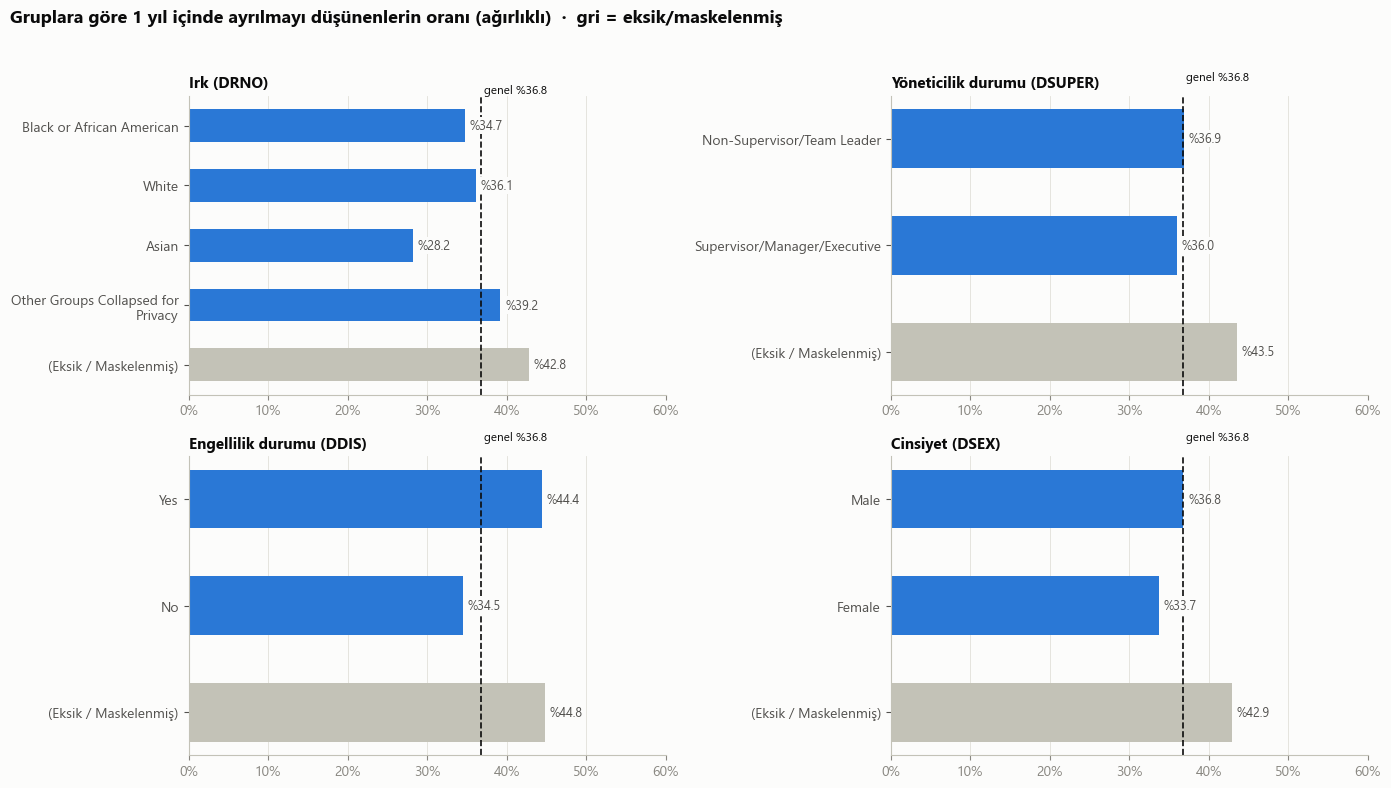

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
genel = etiket_tablolari["DSEX"].loc["TOPLAM", "%_ayrılma_ağırlıklı"]
for ax, (c, t) in zip(axes.flat, etiket_tablolari.items()):
    s = t.drop("TOPLAM")["%_ayrılma_ağırlıklı"][::-1]
    colors = [AXIS if i == MISS else BLUE for i in s.index]
    ax.barh([fill(str(i), 30) for i in s.index], s.values, color=colors, height=0.55)
    ax.axvline(genel, color=INK, lw=1.2, ls="--", zorder=2)
    for y, v in enumerate(s.values):
        ax.text(v + 0.6, y, f"%{v:.1f}", va="center", fontsize=9, color=INK2, zorder=3,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.text(genel + 0.4, len(s) - 0.45, f"genel %{genel:.1f}", fontsize=8.5, color=INK)
    ax.set_xlim(0, 60); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{TR[c]} ({c})", fontsize=11)
fig.suptitle("Gruplara göre 1 yıl içinde ayrılmayı düşünenlerin oranı (ağırlıklı)  ·  gri = eksik/maskelenmiş",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96]); kaydet("02_11_etiket_gruplara_gore")

## 7. Tabloların Excel'e aktarılması

In [22]:
OUT_XLSX = TAB / "FEVS2024_analiz_tablolari.xlsx"
with pd.ExcelWriter(OUT_XLSX) as xw:
    sozluk.to_excel(xw, sheet_name="Degisken_Sozlugu", index=False)
    surekli.round(3).to_excel(xw, sheet_name="Surekli_Istatistik")
    pd.concat(freq_tables, names=["degisken"]).to_excel(xw, sheet_name="Kategorik_Frekans")
    q16.to_excel(xw, sheet_name="Q16_Coklu_Secim")
    likert.round(2).to_excel(xw, sheet_name="Likert_PNN")
    dist.to_excel(xw, sheet_name="Likert_1_5_Dagilim")
    ag.join(ag_idx.round(1)).to_excel(xw, sheet_name="Ajans")
    for c, t in cross_tables.items():
        t.to_excel(xw, sheet_name=f"Capraz_{c}")
    for c, t in etiket_tablolari.items():
        t.to_excel(xw, sheet_name=f"Etiket_{c}")
    df.sample(20000, random_state=1).drop(columns=["agency", "level1"]).to_excel(
        xw, sheet_name="Veri_Orneklem_20bin", index=False)
print("Kaydedildi:", OUT_XLSX)

# Tam veri (etiketli + indeks skorları) – CSV
OUT_CSV = DATA / "fevs2024_etiketli_skorlu.csv"
df.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
print("Kaydedildi:", OUT_CSV)

Kaydedildi: ~\fevs_proje\reports\tables\FEVS2024_analiz_tablolari.xlsx


Kaydedildi: ~\fevs_proje\data\fevs2024_etiketli_skorlu.csv
